# Food classification — dataset 02_denoise_clahe

Compare four models on the team's existing split: CLIP ViT-B/32 zero-shot (no training), HOG + RBF SVM, a CNN trained from scratch, and ImageNet ResNet-50 with only `layer4` and `fc` fine-tuned. Select settings and epochs using validation macro-F1; report the held-out test results. The source template is `04_denoise_clahe_dino.ipynb`.

## Run
1. Put the team's dataset in `data/dataset/02_denoise_clahe/{train,val,test}/<class>/` and its `manifest.csv` and `removed.csv` in `data/dataset/meta/`. Preserve the provided split. For Colab, add a shortcut to the shared `dip-project` folder in My Drive, then use the paths cell to mount Drive and read `dip-project/dataset_zips/02_denoise_clahe.zip`. The zip must contain `02_denoise_clahe/` and `meta/` at its root.
2. Install compatible PyTorch/torchvision, transformers, scikit-learn, scikit-image, OpenCV, pandas, matplotlib, Pillow and joblib. Pretrained CLIP and ResNet weights require internet access on the first run.
3. Run all cells with `RUN_MODE = "smoke"` first, then switch to `"full"`. Outputs are saved separately under `results/smoke/02_denoise_clahe/` and `results/02_denoise_clahe/`.

The template evaluates every configuration on test for reporting, but **only validation macro-F1 determines selection**. Do not use test results to tune further. This run changes the template's classical features and ResNet search space, so it is not an identical-protocol comparison with existing 04 results.


## 0. Configuration
The 02 images are already denoised and CLAHE-processed; do not apply these steps a second time. Use the existing manifest and split.


In [6]:
# ==== the only cell you normally edit ====
DATASET = "02_denoise_clahe"   # "01_original" | "02_denoise_clahe" | "03_denoise_clahe_gsam" | "04_denoise_clahe_dino"
RUN_MODE = "full"                  # "smoke": 20 imgs/class/split, 2 epochs, to test the pipeline | "full": the real run
SEED = 42
RETRAIN = True                     # True: ignore saved checkpoints / grid results and train again

# ---- from here on: identical for every dataset (same as the 03 run) ----
IMG_SIZE = 224
PAD_FILL = (124, 116, 104)          # same grey as the GSAM background (used to pad every dataset to a square)
BATCH_SIZE = 32
EVAL_BATCH_SIZE = 64
LABEL_SMOOTHING = 0.1

CLASSICAL_FEATURES = "hog"  # HOG only
LOGREG_C = [1e-4, 1e-3, 1e-2, 1e-1, 1, 10, 100]
SVM_C = [0.1, 0.3, 1, 2, 3, 5, 10]
SVM_GAMMA_MULT = [0.03, 0.1, 0.3, 1]       # x 1/n_features (= sklearn "scale" after standardising)

CNN_GRID = [dict(n_blocks=n, base=32, dropout=0.3) for n in (3, 4, 5)]
CNN_TRAIN = dict(max_epochs=40, patience=6, lr=1e-3, weight_decay=5e-4)

RESNET_GRID = [dict(unfreeze="layer4", lr=3e-4)]
RESNET_TRAIN = dict(max_epochs=15, patience=4, weight_decay=1e-4)

CLIP_ID = "openai/clip-vit-base-patch32"
TEMPLATE_SETS = {
    "classname": ["{}"],
    "a photo of": ["a photo of {}."],
    "food photo": ["a photo of {}, a type of food."],
    "ensemble": ["a photo of {}, a type of food.", "a close-up photo of {}.", "a photo of a plate of {}.",
                 "a good photo of {}.", "a cropped photo of {}."],
}

EXPECTED_MANIFEST_SHA256 = "79eb1d1cf8a475b8deaa2a301acc64a1c3a334fd4a289c8d45af91c359c3c2a4"
SMOKE_PER_CLASS = 20
if RUN_MODE == "smoke":
    CNN_TRAIN = {**CNN_TRAIN, "max_epochs": 2}
    RESNET_TRAIN = {**RESNET_TRAIN, "max_epochs": 2}
    LOGREG_C, SVM_C, SVM_GAMMA_MULT = [1e-2, 1], [1, 10], [1]

In [7]:
# ==== paths (local VS Code or Colab) ====
import os, sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    # Shared with me folders appear in the mount after adding a shortcut to My Drive.
    DRIVE_DIR = Path("/content/drive/MyDrive/food_classify")  # results are saved here
    ZIP_PATH = Path("/content/drive/MyDrive/dip-project/dataset_zips/02_denoise_clahe.zip")
    # If the shortcut is elsewhere, change ZIP_PATH to its location under MyDrive.
    DATA_ROOT = Path("/content/data/dataset")
    if not (DATA_ROOT / DATASET).exists() or not (DATA_ROOT / "meta" / "manifest.csv").exists():
        import zipfile
        if not ZIP_PATH.is_file():
            raise FileNotFoundError(
                f"ZIP not found: {ZIP_PATH}. In Google Drive, add a shortcut to the shared "
                "dip-project folder in My Drive, or edit ZIP_PATH to the shortcut's actual location."
            )
        DATA_ROOT.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(ZIP_PATH) as z:
            for member in z.infolist():
                target = (DATA_ROOT / member.filename).resolve()
                if not target.is_relative_to(DATA_ROOT.resolve()):
                    raise ValueError(f"Unsafe ZIP path: {member.filename}")
            z.extractall(DATA_ROOT)
    OUT_ROOT = DRIVE_DIR / "results"  # persists after Colab disconnects
else:
    here = Path.cwd().resolve()
    PROJECT = next((p for p in [here, *here.parents] if (p / "data" / "dataset" / DATASET).exists()), None)
    assert PROJECT is not None, f"data/dataset/{DATASET} not found above {here}: unzip the dataset into data/dataset/"
    DATA_ROOT = PROJECT / "data" / "dataset"
    OUT_ROOT = PROJECT / "results"
    os.environ.setdefault("TORCH_HOME", str(PROJECT / "checkpoints" / "torch"))  # reuse downloaded weights
    os.environ.setdefault("HF_HOME", str(PROJECT / "checkpoints" / "hf"))

META = DATA_ROOT / "meta"
OUT = (OUT_ROOT / DATASET) if RUN_MODE == "full" else (OUT_ROOT / "smoke" / DATASET)
CKPT_DIR, FIG_DIR = OUT / "checkpoints", OUT / "figures"
for d in (OUT, CKPT_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)
print("data   :", DATA_ROOT / DATASET)
print("results:", OUT)

data   : /Users/song-pongpanit/Documents/image_project/data/dataset/02_denoise_clahe
results: /Users/song-pongpanit/Documents/image_project/results/02_denoise_clahe


In [8]:
import json, time, random, hashlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as T
from torchinfo import summary
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import precision_recall_fscore_support, f1_score, average_precision_score, confusion_matrix
from sklearn.preprocessing import label_binarize

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"                    # fp16 helps on CUDA; it did not help on the M1
NON_BLOCKING = DEVICE.type == "cuda"
NUM_WORKERS = 0 if sys.platform == "darwin" else 2  # macOS Jupyter can't pickle classes defined in a notebook into workers
pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})


def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def savefig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=120, bbox_inches="tight")


def finish(fig, title, name):
    """Lay out a grid figure with its title above the first row (no overlap), save, show."""
    fig.tight_layout(rect=(0, 0, 1, 1 - 0.55 / fig.get_figheight()))
    fig.suptitle(title, y=1 - 0.12 / fig.get_figheight())
    savefig(fig, name)
    plt.show()


seed_everything()
print(f"python {sys.version.split()[0]} ({sys.executable}) | torch {torch.__version__} | torchvision {torchvision.__version__} | device {DEVICE}")

python 3.13.5 (/usr/local/bin/python3) | torch 2.7.1 | torchvision 0.22.1 | device mps


## 1. Data checks
Check the manifest, split, class balance and potential duplicate images.


In [9]:
sha = hashlib.sha256((META / "manifest.csv").read_bytes()).hexdigest()
assert sha == EXPECTED_MANIFEST_SHA256, f"manifest differs from the team's ({sha}): wrong zip?"

df_all = pd.read_csv(META / "manifest.csv")
df_all["path"] = [str(DATA_ROOT / DATASET / r) for r in df_all.relpath]
missing = [p for p in df_all.path if not os.path.exists(p)]
assert not missing, f"{len(missing)} images in the manifest are missing, e.g. {missing[:3]}"
on_disk = {str(p.relative_to(DATA_ROOT / DATASET)) for p in (DATA_ROOT / DATASET).glob("*/*/*.jpg")}
assert on_disk == set(df_all.relpath), "folder contents and manifest differ"
assert (df_all.relpath.str.split("/").str[0] == df_all.split).all() and \
       (df_all.relpath.str.split("/").str[1] == df_all.label).all(), "folder and manifest split/label disagree"

CLASSES = sorted(df_all.label.unique())
K = len(CLASSES)
CLS2IDX = {c: i for i, c in enumerate(CLASSES)}
df_all["y"] = df_all.label.map(CLS2IDX)

key = df_all.label + "/" + df_all.relpath.str.split("/").str[-1]
assert not key.duplicated().any(), "the same image id appears in more than one split"

counts = df_all.pivot_table(index="label", columns="split", values="relpath", aggfunc="count")[["train", "val", "test"]]
counts.loc["total"] = counts.sum()
display(counts)
assert counts.drop("total").nunique().eq(1).all(), "classes are not balanced"
print("split ratio:", (counts.loc["total"] / counts.loc["total"].sum()).round(3).to_dict())

df = df_all.groupby(["split", "label"], group_keys=False).head(SMOKE_PER_CLASS) if RUN_MODE == "smoke" else df_all
splits = {s: df[df.split == s].reset_index(drop=True) for s in ("train", "val", "test")}
y_split = {s: v.y.values for s, v in splits.items()}
print({s: len(v) for s, v in splits.items()}, "images used in this run")

split,train,val,test
label,,,
baby_back_ribs,578,193,192
bibimbap,578,193,192
chicken_wings,578,193,192
edamame,578,193,192
guacamole,578,193,192
miso_soup,578,193,192
mussels,578,193,192
nachos,578,193,192
paella,578,193,192


split ratio: {'train': 0.6, 'val': 0.2, 'test': 0.199}
{'train': 5780, 'val': 1930, 'test': 1920} images used in this run


In [10]:
removed = pd.read_csv(META / "removed.csv")
removed["label"] = removed.key.str.split("/").str[0]
print(f"{len(removed)} images were removed during cleaning:")
display(pd.crosstab(removed.label, removed.reason, margins=True))

118 images were removed during cleaning:


reason,duplicate,nonfood,wrong_label,All
label,,,,
baby_back_ribs,5,2,7,14
bibimbap,2,4,5,11
chicken_wings,1,5,0,6
edamame,35,0,2,37
guacamole,0,2,3,5
miso_soup,2,0,0,2
mussels,3,1,2,6
nachos,2,2,1,5
paella,4,2,9,15


3 hash groups with >1 image; 3 of them span different splits


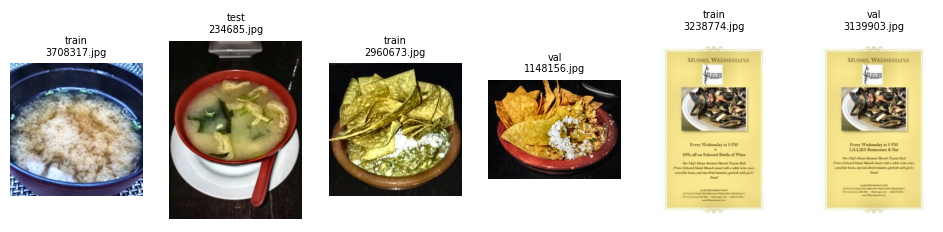

In [11]:
# near-duplicate check across splits (8x8 average hash). Report only: the split is fixed by the team.
def ahash(path):
    g = np.asarray(Image.open(path).convert("L").resize((8, 8), Image.BILINEAR), dtype=np.float32)
    return np.packbits(g > g.mean()).tobytes()

df_all["ahash"] = [ahash(p) for p in df_all.path]
dup = df_all[df_all.duplicated("ahash", keep=False)].sort_values("ahash")
cross = dup.groupby("ahash").filter(lambda g: g.split.nunique() > 1)
print(f"{dup.ahash.nunique()} hash groups with >1 image; {cross.ahash.nunique()} of them span different splits")
if len(cross):
    show = cross.groupby("ahash").head(2).head(12)
    fig, axes = plt.subplots(1, len(show), figsize=(2 * len(show), 2.4), squeeze=False)
    for ax, (_, r) in zip(axes[0], show.iterrows()):
        ax.imshow(Image.open(r.path)); ax.set_title(f"{r.split}\n{r.relpath.split('/')[-1]}", fontsize=7); ax.axis("off")
    plt.show()

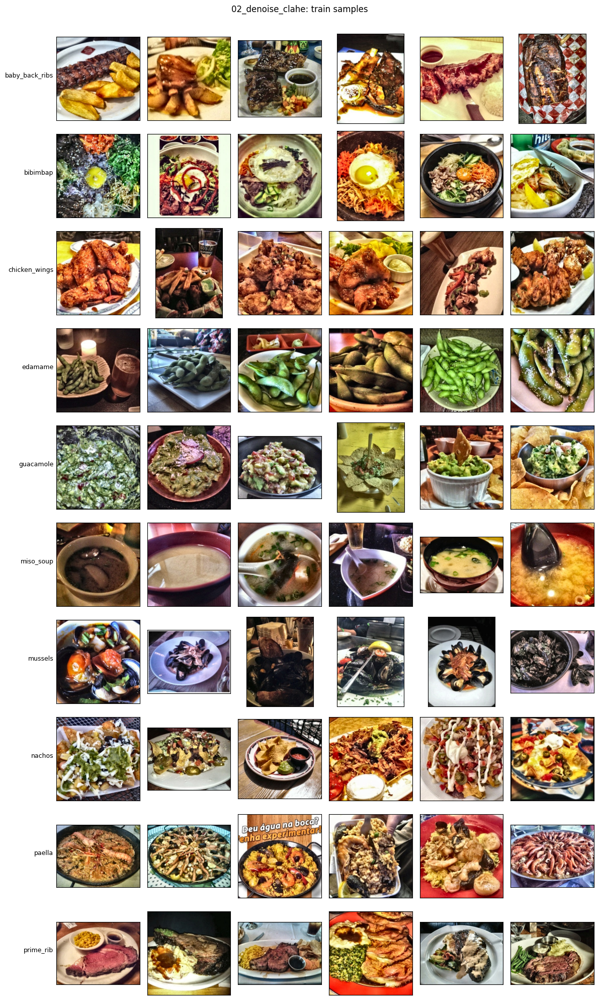

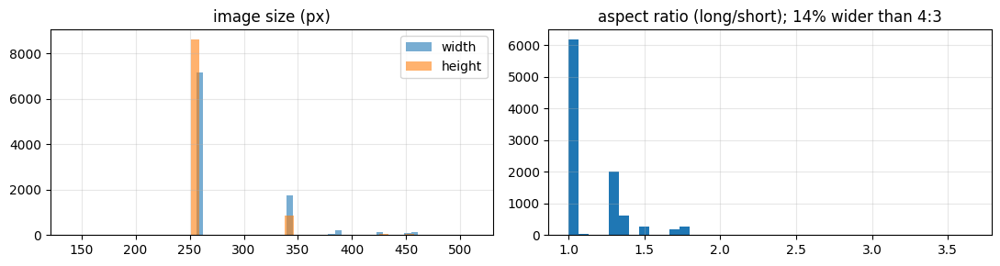

In [12]:
# 6 random training images per class
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(K, 6, figsize=(12, 2 * K))
for i, c in enumerate(CLASSES):
    rows = df_all[(df_all.split == "train") & (df_all.label == c)]
    for j, p in enumerate(rng.choice(rows.path.values, 6, replace=False)):
        ax = axes[i, j]; ax.imshow(Image.open(p)); ax.set_xticks([]); ax.set_yticks([])
        if j == 0: ax.set_ylabel(c, rotation=0, ha="right", fontsize=9)
finish(fig, f"{DATASET}: train samples", "samples")

sizes = np.array([Image.open(p).size for p in df_all.path])
aspect = sizes.max(1) / sizes.min(1)
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
axes[0].hist(sizes[:, 0], bins=40, alpha=0.6, label="width"); axes[0].hist(sizes[:, 1], bins=40, alpha=0.6, label="height")
axes[0].set_title("image size (px)"); axes[0].legend()
axes[1].hist(aspect, bins=40); axes[1].set_title(f"aspect ratio (long/short); {np.mean(aspect > 4 / 3):.0%} wider than 4:3")
plt.tight_layout(); plt.show()

## 2. Input pipeline
Pad to square (grey) → 224×224. Train adds a mild random crop (70–100% of the area) and a horizontal flip.
The same transform is used for CNN and ResNet-50; CLIP and the classical features use the same pad + resize with their own normalisation / size.

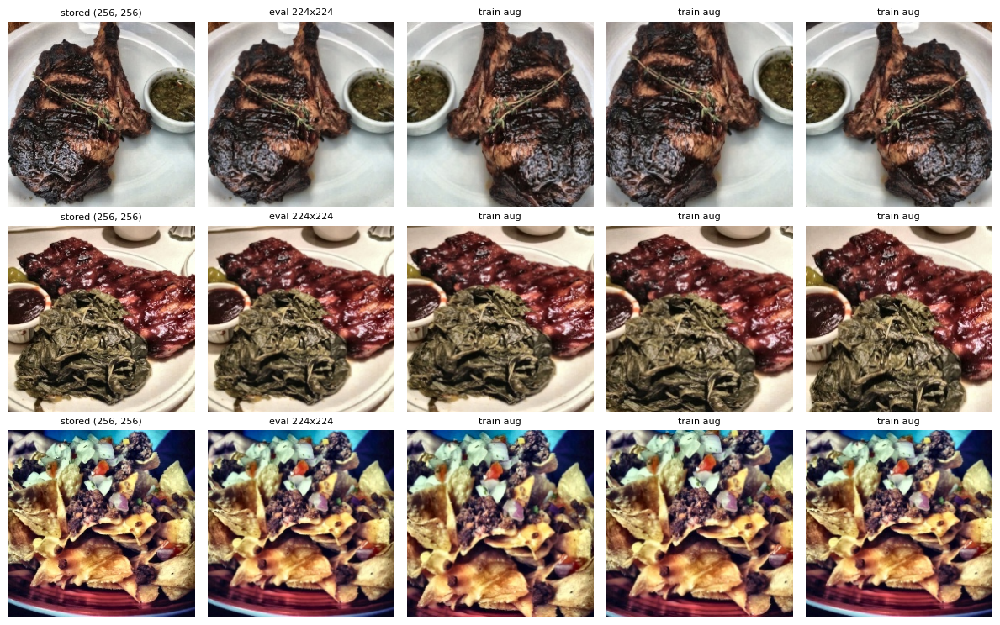

In [13]:
IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
CLIP_MEAN, CLIP_STD = [0.48145466, 0.4578275, 0.40821073], [0.26862954, 0.26130258, 0.27577711]


def pad_to_square(img, fill=PAD_FILL):
    w, h = img.size
    s = max(w, h)
    out = Image.new("RGB", (s, s), fill)
    out.paste(img, ((s - w) // 2, (s - h) // 2))
    return out


train_tf = T.Compose([T.Lambda(pad_to_square),
                      T.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0), ratio=(0.9, 1.1)),
                      T.RandomHorizontalFlip(),
                      T.ToTensor(), T.Normalize(IMAGENET_MEAN, IMAGENET_STD)])
eval_tf = T.Compose([T.Lambda(pad_to_square), T.Resize((IMG_SIZE, IMG_SIZE)),
                     T.ToTensor(), T.Normalize(IMAGENET_MEAN, IMAGENET_STD)])
clip_tf = T.Compose([T.Lambda(pad_to_square), T.Resize((IMG_SIZE, IMG_SIZE)),
                     T.ToTensor(), T.Normalize(CLIP_MEAN, CLIP_STD)])


def show_tensor(t, mean=IMAGENET_MEAN, std=IMAGENET_STD):
    """Normalised CHW tensor -> HWC image in [0, 1] for plotting."""
    x = t.cpu() * torch.tensor(std)[:, None, None] + torch.tensor(mean)[:, None, None]
    return x.clamp(0, 1).permute(1, 2, 0).numpy()


class FoodDataset(Dataset):
    def __init__(self, frame, transform):
        self.paths, self.labels, self.transform = frame.path.tolist(), frame.y.tolist(), transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        return self.transform(Image.open(self.paths[i]).convert("RGB")), self.labels[i]


def make_loader(split, transform, shuffle=False, batch_size=None):
    return DataLoader(FoodDataset(splits[split], transform), batch_size=batch_size or (BATCH_SIZE if shuffle else EVAL_BATCH_SIZE),
                      shuffle=shuffle, num_workers=NUM_WORKERS, pin_memory=DEVICE.type == "cuda",
                      persistent_workers=NUM_WORKERS > 0)


# what the models see
demo = splits["train"].sample(3, random_state=SEED)
fig, axes = plt.subplots(3, 5, figsize=(12, 7.5))
for row, (_, r) in zip(axes, demo.iterrows()):
    img = Image.open(r.path).convert("RGB")
    row[0].imshow(img); row[0].set_title(f"stored {img.size}", fontsize=8)
    row[1].imshow(show_tensor(eval_tf(img))); row[1].set_title("eval 224x224", fontsize=8)
    for ax in row[2:]:
        ax.imshow(show_tensor(train_tf(img))); ax.set_title("train aug", fontsize=8)
    for ax in row: ax.axis("off")
plt.tight_layout(); savefig(fig, "transforms"); plt.show()

## 3. Evaluation toolkit
Report top-1/3/5 accuracy, macro precision, recall and F1, per-class AP, mAP, confusion matrices and prediction examples. All configurations are selected on validation macro-F1. Test scores are recorded for reporting only. The fitted model, configuration, metrics and predictions are saved under the results directory.


In [14]:
RESULTS = {}   # model name -> {"val": {...}, "test": {...}, "config": {...}}


def topk_accuracy(y, scores, k):
    top = np.argsort(-scores, axis=1)[:, :k]
    return float((top == y[:, None]).any(axis=1).mean())


def compute_metrics(y, scores):
    y = np.asarray(y)
    pred = scores.argmax(1)
    p, r, f1, _ = precision_recall_fscore_support(y, pred, average="macro", zero_division=0)
    Y = label_binarize(y, classes=np.arange(K))
    ap = np.array([average_precision_score(Y[:, c], scores[:, c]) for c in range(K)])
    pc_p, pc_r, pc_f, support = precision_recall_fscore_support(y, pred, labels=np.arange(K), zero_division=0)
    per_class = pd.DataFrame({"precision": pc_p, "recall": pc_r, "f1": pc_f, "AP": ap, "support": support}, index=CLASSES)
    summary = {"top1": topk_accuracy(y, scores, 1), "top3": topk_accuracy(y, scores, 3), "top5": topk_accuracy(y, scores, 5),
               "macro_precision": float(p), "macro_recall": float(r), "macro_f1": float(f1), "mAP": float(np.nanmean(ap)), "n": int(len(y))}
    return summary, per_class


def macro_f1(y, scores):
    return f1_score(y, scores.argmax(1), average="macro", zero_division=0)


def plot_confusion(y, pred, title, name):
    cm = confusion_matrix(y, pred, labels=np.arange(K))
    cmn = cm / cm.sum(1, keepdims=True).clip(min=1)
    fig, axes = plt.subplots(1, 2, figsize=(18, 7.5))
    for ax, m, fmt, sub in [(axes[0], cm, "d", "counts"), (axes[1], cmn, ".2f", "row-normalised (diagonal = recall)")]:
        im = ax.imshow(m, cmap="Blues")
        ax.set_xticks(range(K), CLASSES, rotation=45, ha="right"); ax.set_yticks(range(K), CLASSES); ax.grid(False)
        for i in range(K):
            for j in range(K):
                ax.text(j, i, format(m[i, j], fmt), ha="center", va="center", fontsize=8,
                        color="white" if m[i, j] > m.max() / 2 else "black")
        ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(f"{title}: {sub}")
        fig.colorbar(im, ax=ax, fraction=0.046)
    plt.tight_layout(); savefig(fig, f"{name}_confusion"); plt.show()
    off = [(CLASSES[i], CLASSES[j], int(cm[i, j])) for i in range(K) for j in range(K) if i != j and cm[i, j] > 0]
    return pd.DataFrame(sorted(off, key=lambda t: -t[2])[:8], columns=["true", "predicted", "count"])


def show_predictions(frame, y, scores, correct, title, name, n=12, is_prob=True):
    pred = scores.argmax(1)
    idx = np.flatnonzero((pred == y) if correct else (pred != y))
    if len(idx) == 0:
        print("no", "correct" if correct else "wrong", "predictions"); return
    idx = np.random.default_rng(SEED).choice(idx, min(n, len(idx)), replace=False)
    cols = 6
    rows = int(np.ceil(len(idx) / cols))
    row_h = 3.3 if correct else 3.7          # room for the 2- or 3-line titles above each image
    fig, axes = plt.subplots(rows, cols, figsize=(2.6 * cols, row_h * rows), squeeze=False)
    tag = "p" if is_prob else "s"
    for ax, i in zip(axes.ravel(), idx):
        top = np.argsort(-scores[i])[:2]
        ax.imshow(Image.open(frame.path[i]))
        txt = f"T: {CLASSES[y[i]]}\nP: {CLASSES[top[0]]} ({tag}={scores[i, top[0]]:.2f})"
        if not correct:
            txt += f"\n2nd: {CLASSES[top[1]]} ({scores[i, top[1]]:.2f})"
        ax.set_title(txt, fontsize=8, color="green" if correct else "red")
    for ax in axes.ravel(): ax.axis("off")
    finish(fig, title, name)


def save_predictions(name, split, y, scores):
    out = splits[split][["relpath", "label"]].copy()
    out["y_true"], out["y_pred"] = y, scores.argmax(1)
    out["pred_label"] = [CLASSES[i] for i in out.y_pred]
    for c in range(K):
        out[f"score_{CLASSES[c]}"] = scores[:, c]
    out.to_csv(OUT / name / f"predictions_{split}.csv", index=False)


def report_model(name, y_val, s_val, y_test, s_test, config, is_prob=True, *, y_train, s_train):
    """Final evaluation of a chosen model: val + test metrics, confusion matrix, examples, saved files."""
    (OUT / name).mkdir(exist_ok=True)
    train_metrics, _ = compute_metrics(y_train, s_train)
    sv, _ = compute_metrics(y_val, s_val)
    st, per_class = compute_metrics(y_test, s_test)
    RESULTS[name] = {"train": train_metrics, "val": sv, "test": st, "config": config}
    display(pd.DataFrame([train_metrics, sv, st], index=["train", "val", "test"]))
    display(per_class)
    display(plot_confusion(y_test, s_test.argmax(1), f"{name} (test)", name))
    show_predictions(splits["test"], y_test, s_test, True, f"{name}: correct test predictions", f"{name}_correct", is_prob=is_prob)
    show_predictions(splits["test"], y_test, s_test, False, f"{name}: wrong test predictions", f"{name}_wrong", is_prob=is_prob)
    save_predictions(name, "val", y_val, s_val)
    save_predictions(name, "test", y_test, s_test)
    per_class.to_csv(OUT / name / "per_class_test.csv")
    with open(OUT / name / "metrics.json", "w") as f:
        json.dump({"dataset": DATASET, "model": name, "seed": SEED, "run_mode": RUN_MODE, **RESULTS[name]}, f, indent=2, default=str)


def save_final(name, kind, model, arch=None, metrics=None):
    """Save a model as results/<dataset>/<name>/model.{pt,joblib} + config.json: the chosen model (after report_model) or any tried config.
    kind: "cnn" | "resnet50" | "clip" (torch, state_dict + architecture) or "sklearn" (whole fitted pipeline)."""
    import joblib
    d = OUT / name
    d.mkdir(parents=True, exist_ok=True)
    arch = json.loads(json.dumps(arch or {}, default=str))   # plain Python types, so torch.load(weights_only=True) can read it
    metrics = metrics or RESULTS.get(name, {})
    if kind == "sklearn":
        file = "model.joblib"
        joblib.dump(model, d / file)
    elif kind == "clip":
        file = "model.pt"
        torch.save({"kind": kind, "arch": arch, "classes": CLASSES, "text_emb": model.text_emb.cpu()}, d / file)
    else:
        file = "model.pt"
        torch.save({"kind": kind, "arch": arch, "classes": CLASSES,
                    "state_dict": {k: v.cpu() for k, v in model.state_dict().items()}}, d / file)
    config = {"dataset": DATASET, "model": name, "kind": kind, "file": file, "arch": arch, "classes": CLASSES,
              "preprocessing": {"pad_to_square_fill": PAD_FILL, "img_size": IMG_SIZE,
                                "normalize": "clip" if kind == "clip" else "imagenet",
                                "classical_features": CLASSICAL_FEATURES if kind == "sklearn" else None},
              "seed": SEED, "run_mode": RUN_MODE, "torch": torch.__version__,
              "val_macro_f1": metrics.get("val", {}).get("macro_f1"),
              "test_macro_f1": metrics.get("test", {}).get("macro_f1"),
              "saved_at": time.strftime("%Y-%m-%d %H:%M:%S")}
    with open(d / "config.json", "w") as f:
        json.dump(config, f, indent=2, default=str)
    size = (d / file).stat().st_size / 1e6
    print(f"saved {d / file} ({size:.1f} MB) + config.json")


ALL_DIR = OUT / "all_models"   # every config tried: model + config.json + metrics.json + scores.npz
ALL_DIR.mkdir(exist_ok=True)
CONFIGS, CHOSEN = {}, {}       # config name -> its val/test metrics; model type -> the config chosen on val


def config_done(name, arch):
    """Metrics of a config already trained, scored and saved with this arch, else None (then it is trained / scored now)."""
    p = ALL_DIR / name / "metrics.json"
    if RETRAIN or not p.exists() or not (ALL_DIR / name / "scores.npz").exists():
        return None
    res = json.loads(p.read_text())
    if res.get("arch") != json.loads(json.dumps(arch, default=str)):
        return None
    CONFIGS[name] = res
    return res


def record_config(name, family, kind, model, arch, scores, train_f1):
    """Score one tried config on val and test, save it to all_models/<name>/ and remember it.
    scores: {"val": (y, s), "test": (y, s)}. Test is recorded for the report; choosing uses val only."""
    arch = json.loads(json.dumps(arch, default=str))
    res = {"model": name, "family": family, "kind": kind, "arch": arch, "train_f1": float(train_f1),
           **{sp: compute_metrics(*scores[sp])[0] for sp in ("val", "test")}}
    save_final(f"all_models/{name}", kind, model, arch, metrics=res)
    np.savez(ALL_DIR / name / "scores.npz", **{f"{sp}_{k}": v for sp, (y, s) in scores.items() for k, v in (("y", y), ("s", s))})
    with open(ALL_DIR / name / "metrics.json", "w") as f:
        json.dump({"dataset": DATASET, **res}, f, indent=2, default=str)
    CONFIGS[name] = res
    return res


def config_scores(name):
    """(y_val, s_val, y_test, s_test) of a recorded config, read back from all_models/<name>/scores.npz."""
    z = np.load(ALL_DIR / name / "scores.npz")
    return z["val_y"], z["val_s"], z["test_y"], z["test_s"]

In [15]:
# shared PyTorch training loop (CNN and ResNet-50)
SCALER = torch.amp.GradScaler("cuda", enabled=USE_AMP)


def set_train_mode(model):
    """train() but keep frozen BatchNorm layers in eval mode, so a frozen backbone's running stats don't change."""
    model.train()
    for m in model.modules():
        if isinstance(m, nn.modules.batchnorm._BatchNorm) and not any(p.requires_grad for p in m.parameters()):
            m.eval()


def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    set_train_mode(model) if training else model.eval()
    total, ys, ps = 0.0, [], []
    for x, y_cpu in loader:
        # non_blocking copies only on CUDA: on MPS with torch <= 2.12 they can deliver corrupted labels
        x, y = x.to(DEVICE, non_blocking=NON_BLOCKING), y_cpu.to(DEVICE, non_blocking=NON_BLOCKING)
        with torch.set_grad_enabled(training), torch.autocast(DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            logits = model(x)
            loss = F.cross_entropy(logits, y, label_smoothing=LABEL_SMOOTHING if training else 0.0)
        if training:
            optimizer.zero_grad(set_to_none=True)
            SCALER.scale(loss).backward()
            SCALER.step(optimizer)
            SCALER.update()
        total += loss.item() * len(y)
        ys.append(y_cpu); ps.append(logits.detach().float().softmax(1).cpu())
    y, p = torch.cat(ys).numpy(), torch.cat(ps).numpy()
    return total / len(y), y, p


def fit(name, build, cfg, max_epochs, patience, lr, weight_decay):
    """Train with AdamW + cosine LR, keep the epoch with the best val macro-F1, stop after `patience` epochs without gain.
    Checkpoint files carry a hash of the config, so changing a grid value never reloads a stale model."""
    tag = hashlib.md5(str((cfg, max_epochs, patience, lr, weight_decay, LABEL_SMOOTHING, IMG_SIZE)).encode()).hexdigest()[:8]
    ckpt, hist_path = CKPT_DIR / f"{name}_{tag}.pt", CKPT_DIR / f"{name}_{tag}_history.csv"
    seed_everything()
    model = build().to(DEVICE)
    if ckpt.exists() and hist_path.exists() and not RETRAIN:
        model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
        print(f"{name}: loaded saved model {ckpt.name}")
        return model, pd.read_csv(hist_path), ckpt
    n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"{name}: {n_train / 1e6:.2f}M trainable params")
    opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=lr, weight_decay=weight_decay)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=max_epochs)
    train_dl, val_dl = make_loader("train", train_tf, shuffle=True), make_loader("val", eval_tf)
    rows, best, best_epoch, wait = [], -1.0, 0, 0
    for epoch in range(1, max_epochs + 1):
        t0, lr_now = time.time(), opt.param_groups[0]["lr"]
        tr_loss, tr_y, tr_p = run_epoch(model, train_dl, opt)
        va_loss, va_y, va_p = run_epoch(model, val_dl)
        sched.step()
        row = dict(epoch=epoch, lr=lr_now, train_loss=tr_loss, val_loss=va_loss,
                   train_acc=(tr_p.argmax(1) == tr_y).mean(), val_acc=(va_p.argmax(1) == va_y).mean(),
                   train_f1=macro_f1(tr_y, tr_p), val_f1=macro_f1(va_y, va_p), sec=time.time() - t0)
        rows.append(row)
        print(f"  ep {epoch:2d} | loss {tr_loss:.3f}/{va_loss:.3f} | F1 {row['train_f1']:.3f}/{row['val_f1']:.3f} | {row['sec']:.0f}s")
        if row["val_f1"] > best:
            best, best_epoch, wait = row["val_f1"], epoch, 0
            torch.save(model.state_dict(), ckpt)
        else:
            wait += 1
            if wait >= patience:
                print(f"  early stop: no val gain for {patience} epochs")
                break
    hist = pd.DataFrame(rows)
    hist["best"] = hist.epoch == best_epoch
    hist.to_csv(hist_path, index=False)
    model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
    return model, hist, ckpt


def load_trained(ckpt, build):
    model = build().to(DEVICE)
    model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
    return model.eval()


@torch.no_grad()
def predict(model, split, transform=None):
    _, y, p = run_epoch(model, make_loader(split, transform or eval_tf))
    return y, p


def plot_learning_curves(hists, title, name):
    """One row per config: loss and macro-F1 per epoch, train vs val, dashed line at the kept epoch."""
    fig, axes = plt.subplots(len(hists), 2, figsize=(12, 3 * len(hists)), squeeze=False)
    for row, (cfg_name, h) in zip(axes, hists.items()):
        best = h.loc[h.best, "epoch"].iloc[0]
        for ax, metric in zip(row, ("loss", "f1")):
            ax.plot(h.epoch, h[f"train_{metric}"], "o-", ms=3, label="train")
            ax.plot(h.epoch, h[f"val_{metric}"], "o-", ms=3, label="val")
            ax.axvline(best, ls="--", c="gray", lw=1)
            ax.set_title(f"{cfg_name}: {'loss' if metric == 'loss' else 'macro-F1'} (kept epoch {best})", fontsize=10)
            ax.set_xlabel("epoch"); ax.legend()
            ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    finish(fig, title, name)


def plot_grid_summary(table, x, title, name, logx=False):
    """Train vs val macro-F1 at the kept epoch for each config: the 'elbow' plot."""
    fig, ax = plt.subplots(figsize=(6.5, 4))
    ax.plot(table[x].astype(str) if not logx else table[x], table.train_f1, "o-", label="train")
    ax.plot(table[x].astype(str) if not logx else table[x], table.val_f1, "o-", label="val")
    if logx: ax.set_xscale("log")
    best = table.val_f1.idxmax()
    ax.scatter([table[x].astype(str)[best] if not logx else table[x][best]], [table.val_f1[best]], s=160,
               facecolors="none", edgecolors="red", lw=2, label="chosen (best val)", zorder=5)
    ax.set_xlabel(x); ax.set_ylabel("macro-F1"); ax.set_title(title); ax.legend()
    plt.tight_layout(); savefig(fig, name); plt.show()

## 4. Model 1 — CLIP ViT-B/32 zero-shot (baseline)
No training: each class name goes into a text prompt, and the image is assigned to the class whose text embedding is closest.
A plain ImageNet ResNet can't do this (its output is the 1,000 ImageNet classes), which is why CLIP is the zero-shot baseline.
The only choice is the prompt template, picked on val. There is no train curve because nothing is fitted.

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 61230.72it/s]


,templates,name,val_top1,val_f1
0,classname,clip_classname,0.9254,0.9237
1,a photo of,clip_a_photo_of,0.9394,0.9383
2,food photo,clip_food_photo,0.9446,0.9444
3,ensemble,clip_ensemble,0.9440,0.9434


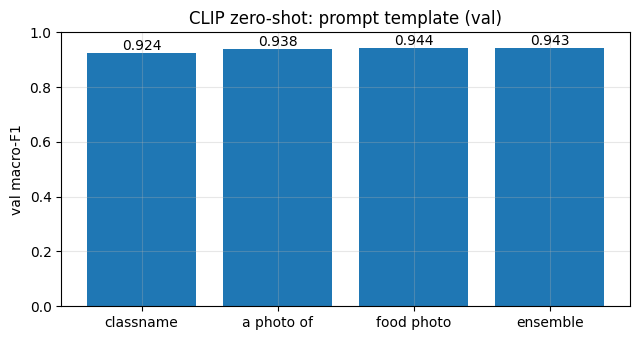

chosen templates: food photo


,top1,top3,top5,macro_precision,macro_recall,macro_f1,mAP,n
train,0.9341,0.9953,0.9986,0.9366,0.9341,0.9339,0.9847,5780
val,0.9446,0.9948,0.9984,0.9470,0.9446,0.9444,0.9877,1930
test,0.9333,0.9943,0.9979,0.9360,0.9333,0.9332,0.9834,1920


,precision,recall,f1,AP,support
baby_back_ribs,0.9152,0.7865,0.8459,0.9403,192
bibimbap,0.9786,0.9531,0.9657,0.9919,192
chicken_wings,0.9433,0.9531,0.9482,0.9910,192
edamame,0.9846,1.0000,0.9922,1.0000,192
guacamole,0.9721,0.9062,0.9380,0.9913,192
miso_soup,0.9643,0.9844,0.9742,0.9984,192
mussels,0.9622,0.9271,0.9443,0.9919,192
nachos,0.8889,0.9583,0.9223,0.9863,192
paella,0.9405,0.9062,0.9231,0.9698,192
prime_rib,0.8106,0.9583,0.8783,0.9731,192


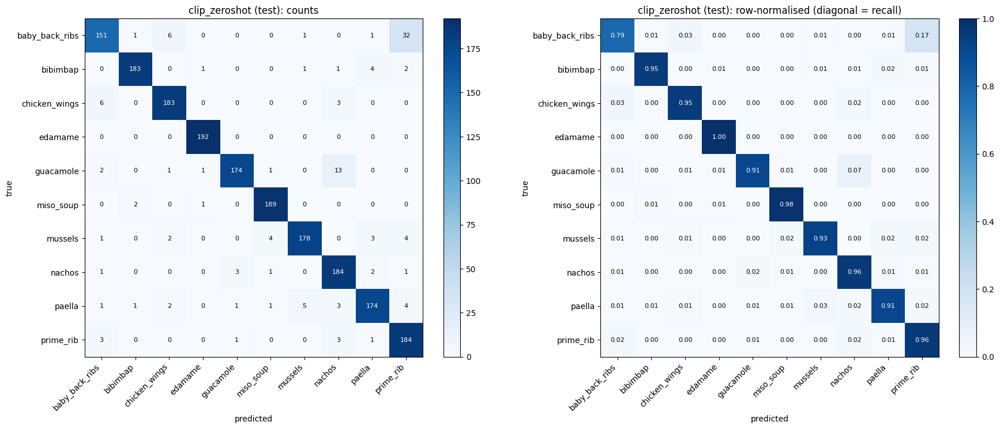

,true,predicted,count
0,baby_back_ribs,prime_rib,32
1,guacamole,nachos,13
2,baby_back_ribs,chicken_wings,6
3,chicken_wings,baby_back_ribs,6
4,paella,mussels,5
5,bibimbap,paella,4
6,mussels,miso_soup,4
7,mussels,prime_rib,4


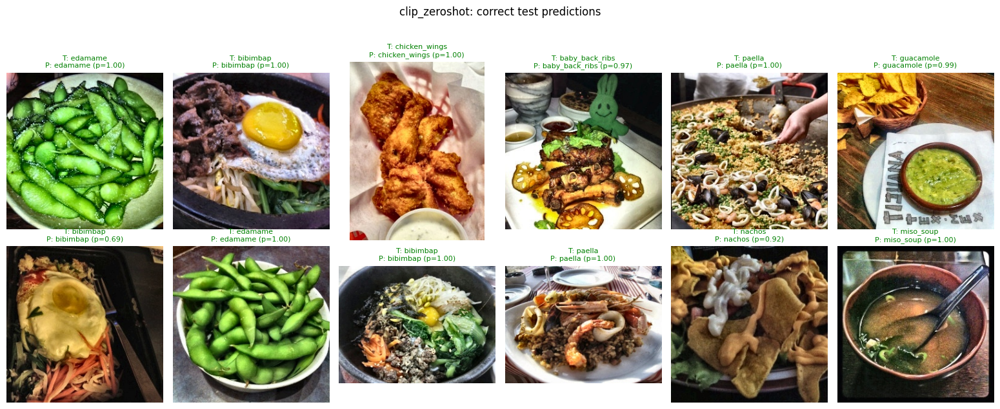

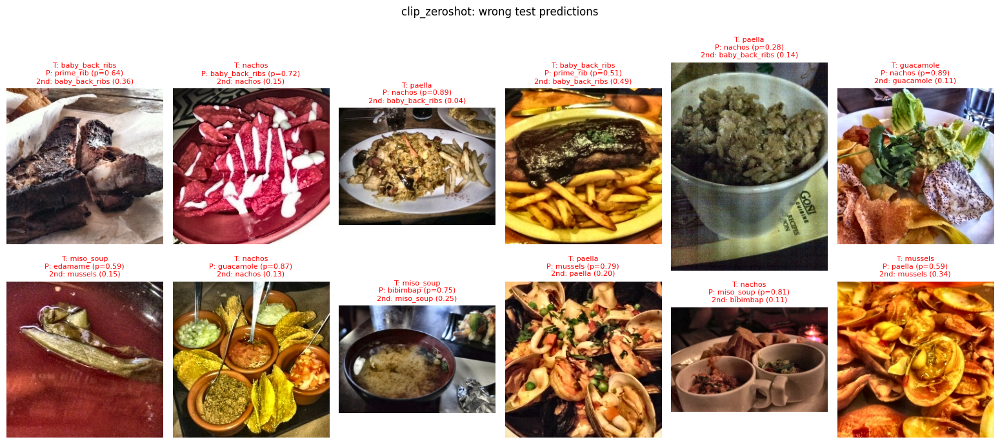

saved /Users/song-pongpanit/Documents/image_project/results/02_denoise_clahe/clip_zeroshot/model.pt (0.0 MB) + config.json


In [69]:
from transformers import CLIPModel, AutoTokenizer

clip = CLIPModel.from_pretrained(CLIP_ID).to(DEVICE).eval()
for p in clip.parameters():
    p.requires_grad_(False)
clip_tok = AutoTokenizer.from_pretrained(CLIP_ID)


@torch.no_grad()
def clip_text_embeddings(templates):
    embs = []
    for c in CLASSES:
        t = clip_tok([tpl.format(c.replace("_", " ")) for tpl in templates], padding=True, return_tensors="pt").to(DEVICE)
        e = clip.text_projection(clip.text_model(input_ids=t["input_ids"], attention_mask=t["attention_mask"]).pooler_output)
        embs.append(F.normalize(F.normalize(e, dim=-1).mean(0), dim=0))
    return torch.stack(embs)


class CLIPZeroShot(nn.Module):
    """Image -> class logits (scaled cosine similarity to the class text embeddings)."""
    def __init__(self, clip, text_emb):
        super().__init__()
        self.clip = clip
        self.register_buffer("text_emb", text_emb)

    def forward(self, x):
        f = self.clip.visual_projection(self.clip.vision_model(pixel_values=x).pooler_output)
        return self.clip.logit_scale.exp() * F.normalize(f, dim=-1) @ self.text_emb.T


@torch.no_grad()
def clip_image_embeddings(split):
    cache = OUT / f"clip_img_{split}.pt"
    if cache.exists() and not RETRAIN:
        return torch.load(cache).to(DEVICE)
    feats = []
    for x, _ in make_loader(split, clip_tf):
        f = clip.visual_projection(clip.vision_model(pixel_values=x.to(DEVICE)).pooler_output)
        feats.append(F.normalize(f, dim=-1))
    feats = torch.cat(feats)
    torch.save(feats.cpu(), cache)
    return feats



img_emb = {s: clip_image_embeddings(s) for s in ("val", "test")}
scale = clip.logit_scale.exp()
rows = []
for tname, templates in TEMPLATE_SETS.items():
    name, arch = "clip_" + tname.replace(" ", "_"), {"clip_id": CLIP_ID, "templates": templates}
    res = config_done(name, arch)
    if res is None:
        model = CLIPZeroShot(clip, clip_text_embeddings(templates)).eval()
        sc = {sp: (y_split[sp], (scale * img_emb[sp] @ model.text_emb.T).softmax(1).cpu().numpy()) for sp in ("val", "test")}
        res = record_config(name, "clip_zeroshot", "clip", model, arch, sc, train_f1=float("nan"))   # nothing is trained
    rows.append({"templates": tname, "name": name, "val_top1": res["val"]["top1"], "val_f1": res["val"]["macro_f1"]})
clip_grid = pd.DataFrame(rows)
display(clip_grid)

fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.bar(clip_grid.templates, clip_grid.val_f1)
for i, v in enumerate(clip_grid.val_f1): ax.text(i, v, f"{v:.3f}", ha="center", va="bottom")
ax.set_ylabel("val macro-F1"); ax.set_title("CLIP zero-shot: prompt template (val)"); ax.set_ylim(0, 1)
plt.tight_layout(); savefig(fig, "clip_templates"); plt.show()

best_clip = clip_grid.loc[clip_grid.val_f1.idxmax()]
CHOSEN["clip_zeroshot"] = best_clip["name"]
clip_model = CLIPZeroShot(clip, clip_text_embeddings(TEMPLATE_SETS[best_clip.templates])).eval()   # kept for Grad-CAM
print("chosen templates:", best_clip.templates)
y_train, s_train = predict(clip_model, "train", transform=clip_tf)
report_model("clip_zeroshot", *config_scores(best_clip["name"]), {"templates": TEMPLATE_SETS[best_clip.templates]},
             y_train=y_train, s_train=s_train)
save_final("clip_zeroshot", "clip", clip_model, {"clip_id": CLIP_ID, "templates": TEMPLATE_SETS[best_clip.templates]})

## 5. Model 2 — HOG + SVM
Extract HOG from grayscale images, standardize features using training data only, and select RBF SVM hyperparameters by validation macro-F1. SVM decision scores are rankings, not calibrated probabilities.


In [16]:
import cv2
from joblib import Parallel, delayed
from skimage.feature import hog, local_binary_pattern
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.exceptions import ConvergenceWarning
import joblib


def handcrafted(path):
    rgb = np.asarray(pad_to_square(Image.open(path).convert("RGB")).resize((128, 128), Image.BILINEAR))
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    return hog(gray, orientations=9, pixels_per_cell=(16, 16),
               cells_per_block=(2, 2), block_norm="L2-Hys").astype(np.float32)


def load_features(split):
    cache = OUT / f"features_{CLASSICAL_FEATURES}_{split}.npz"
    if cache.exists() and not RETRAIN:
        z = np.load(cache, allow_pickle=True)
        if list(z["relpath"]) == splits[split].relpath.tolist():
            return z["X"]
    t0 = time.time()
    if CLASSICAL_FEATURES == "hog":
        X = np.stack(Parallel(n_jobs=-1, batch_size=32)(delayed(handcrafted)(p) for p in splits[split].path))
    else:
        raise ValueError("Only HOG features are supported")
    np.savez(cache, X=X, relpath=splits[split].relpath.values)
    print(f"{split}: features {X.shape} in {time.time() - t0:.0f}s")
    return X


X = {s: load_features(s) for s in ("train", "val", "test")}
print({s: v.shape for s, v in X.items()})
# One reproducible augmented view per training image, using the CNN/ResNet crop and flip settings.
hog_train_aug = T.Compose([T.Lambda(pad_to_square),
    T.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0), ratio=(0.9, 1.1)),
    T.RandomHorizontalFlip(), T.Resize((128, 128))])

def augmented_hog(path):
    img = hog_train_aug(Image.open(path).convert("RGB"))
    gray = cv2.cvtColor(np.asarray(img), cv2.COLOR_RGB2GRAY)
    return hog(gray, orientations=9, pixels_per_cell=(16, 16),
               cells_per_block=(2, 2), block_norm="L2-Hys").astype(np.float32)

seed_everything()
X_aug = np.stack([augmented_hog(p) for p in splits["train"].path])
X_fit = np.concatenate([X["train"], X_aug])
y_fit = np.tile(y_split["train"], 2)
print("SVM training features:", X_fit.shape)


train: features (5780, 1764) in 2s
val: features (1930, 1764) in 1s
test: features (1920, 1764) in 1s
{'train': (5780, 1764), 'val': (1930, 1764), 'test': (1920, 1764)}
SVM training features: (11560, 1764)


In [17]:
def sweep(family, make_model, grid, name_of):
    """Fit every config on train and score train / val / test; each fitted model is saved, so a re-run loads results instead of refitting."""
    rows = []
    for cfg in grid:
        name, arch = name_of(cfg), {"features": CLASSICAL_FEATURES, **cfg}
        res = config_done(name, arch)
        if res is None:
            t0 = time.time()
            with warnings.catch_warnings():
                warnings.simplefilter("ignore", ConvergenceWarning)
                m = make_model(**cfg).fit(X_fit, y_fit)
            score = m.predict_proba if hasattr(m, "predict_proba") else m.decision_function
            res = record_config(name, family, "sklearn", m, arch, {sp: (y_split[sp], score(X[sp])) for sp in ("val", "test")},
                                train_f1=macro_f1(y_split["train"], score(X["train"])))
            print(f"  {cfg} -> train {res['train_f1']:.3f} | val {res['val']['macro_f1']:.3f} | {time.time() - t0:.0f}s")
        rows.append({**cfg, "name": name, "train_f1": res["train_f1"], "val_f1": res["val"]["macro_f1"]})
    return pd.DataFrame(rows)


n_feat = X["train"].shape[1]
def make_svm(C, gamma_mult):
    return make_pipeline(StandardScaler(), SVC(C=C, gamma=gamma_mult / n_feat, kernel="rbf", decision_function_shape="ovr"))


In [ ]:
print("SVM (RBF)")
svm_grid = sweep("svm", make_svm, [dict(C=c, gamma_mult=g) for g in SVM_GAMMA_MULT for c in SVM_C],
                 lambda c: f"svm_aug1_C{c['C']:g}_g{c['gamma_mult']:g}")
display(svm_grid.pivot(index="gamma_mult", columns="C", values="val_f1").style.background_gradient(cmap="Blues").format("{:.3f}"))

fig, ax = plt.subplots(figsize=(7, 4))
for i, (g, t) in enumerate(svm_grid.groupby("gamma_mult")):
    ax.plot(t.C, t.train_f1, "--", c=f"C{i}", label=f"train, gamma x{g}")
    ax.plot(t.C, t.val_f1, "o-", c=f"C{i}", label=f"val, gamma x{g}")
b = svm_grid.val_f1.idxmax()
ax.scatter([svm_grid.C[b]], [svm_grid.val_f1[b]], s=160, facecolors="none", edgecolors="red", lw=2, zorder=5, label="chosen")
ax.set_xscale("log"); ax.set_xlabel("C"); ax.set_ylabel("macro-F1"); ax.set_title("SVM (RBF): validation curves"); ax.legend(fontsize=7)
plt.tight_layout(); savefig(fig, "svm_curve"); plt.show()

SVM (RBF)
saved /Users/song-pongpanit/Documents/image_project/results/02_denoise_clahe/all_models/svm_aug1_C0.1_g0.3/model.joblib (162.9 MB) + config.json
  {'C': 0.1, 'gamma_mult': 0.3} -> train 0.321 | val 0.265 | 203s
saved /Users/song-pongpanit/Documents/image_project/results/02_denoise_clahe/all_models/svm_aug1_C1_g0.3/model.joblib (158.0 MB) + config.json
  {'C': 1, 'gamma_mult': 0.3} -> train 0.524 | val 0.317 | 185s
saved /Users/song-pongpanit/Documents/image_project/results/02_denoise_clahe/all_models/svm_aug1_C10_g0.3/model.joblib (157.1 MB) + config.json
  {'C': 10, 'gamma_mult': 0.3} -> train 0.958 | val 0.334 | 177s
saved /Users/song-pongpanit/Documents/image_project/results/02_denoise_clahe/all_models/svm_aug1_C100_g0.3/model.joblib (157.4 MB) + config.json
  {'C': 100, 'gamma_mult': 0.3} -> train 1.000 | val 0.335 | 196s


In [21]:
best_svm = svm_grid.loc[svm_grid.val_f1.idxmax()]
CHOSEN["svm"] = best_svm["name"]
svm = joblib.load(ALL_DIR / best_svm["name"] / "model.joblib")
print(f"SVM, chosen C = {best_svm.C}, gamma = {best_svm.gamma_mult} / n_features")
# SVC has no calibrated probabilities; the one-vs-rest decision values rank the classes, which is all top-k and AP need
y_train, s_train = y_split["train"], svm.decision_function(X["train"])
report_model("svm", *config_scores(best_svm["name"]),
             {"features": CLASSICAL_FEATURES, "C": float(best_svm.C), "gamma_mult": float(best_svm.gamma_mult)},
             is_prob=False, y_train=y_train, s_train=s_train)
save_final("svm", "sklearn", svm, {"features": CLASSICAL_FEATURES, "C": float(best_svm.C), "gamma_mult": float(best_svm.gamma_mult)})

NameError: name 'svm_grid' is not defined

## 6. Model 3 — CNN from scratch
VGG-style blocks of `[conv3×3-BN-ReLU] ×2 → maxpool`, channels doubling per block (32, 64, 128, …), then global average pooling → dropout → linear.
The tuning question is **depth** (3, 4 or 5 blocks); epochs are set by early stopping on val macro-F1.

Two kinds of graph:
1. **Learning curves** per config (loss and macro-F1 per epoch). Overfitting shows as train still improving while val flattens or gets worse. The dashed line marks the kept epoch.
2. **Train vs val against depth** at each config's kept epoch: the elbow plot.

Train scores are measured during the training pass (with augmentation and dropout on), which is standard and slightly underestimates them.

The table's `stopped` column says whether a config early-stopped or hit `max_epochs`. One that hit the limit was still improving, so its score is a lower bound (in the 03 run the 5-block CNN did). The limit stays at 40 so 04 is comparable with 03.

cnn_d3: loaded saved model cnn_d3_1fa1170c.pt
cnn_d4: loaded saved model cnn_d4_c95dd142.pt
cnn_d5: loaded saved model cnn_d5_588ac846.pt


,n_blocks,base,dropout,name,epoch,epochs_run,stopped,train_f1,val_f1
0,3,32,0.3,cnn_d3,39,40,epoch limit,0.8140,0.8231
1,4,32,0.3,cnn_d4,11,17,early stop,0.7072,0.7015
2,5,32,0.3,cnn_d5,38,40,epoch limit,0.9148,0.8495


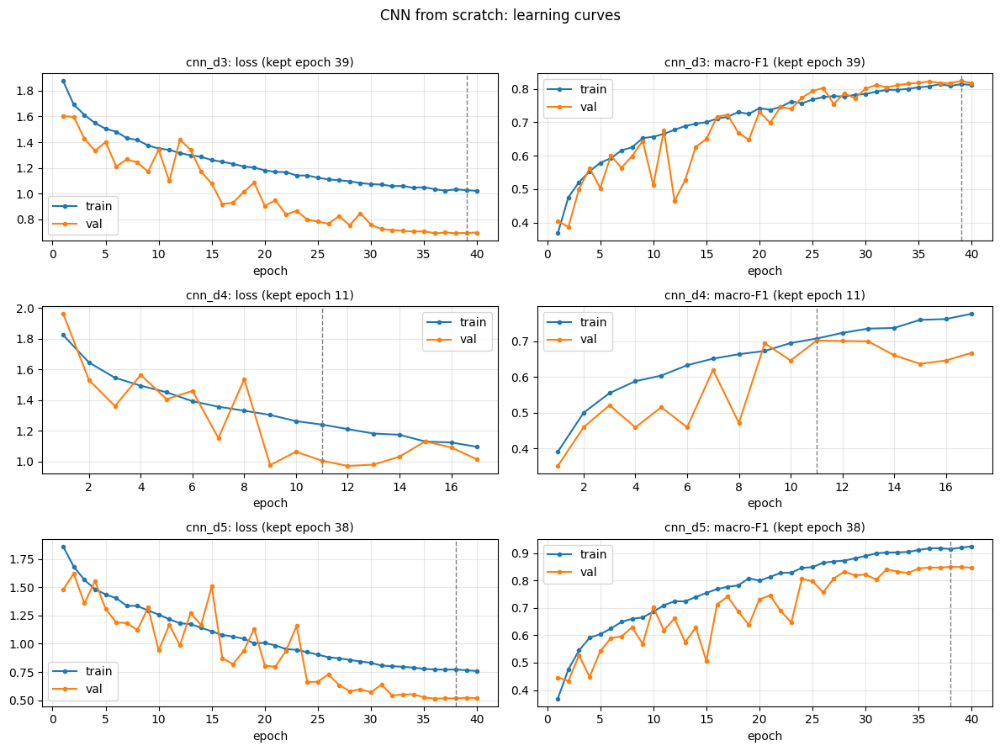

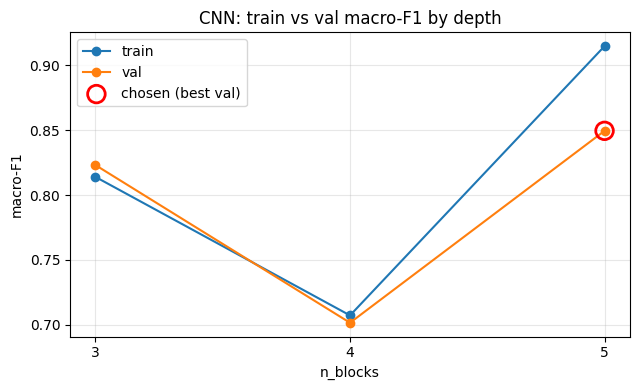

In [74]:
class SimpleCNN(nn.Module):
    def __init__(self, n_blocks=4, base=32, dropout=0.3, n_classes=K):
        super().__init__()
        layers, c_in = [], 3
        for i in range(n_blocks):
            c = base * 2 ** i
            layers += [nn.Conv2d(c_in, c, 3, padding=1, bias=False), nn.BatchNorm2d(c), nn.ReLU(inplace=True),
                       nn.Conv2d(c, c, 3, padding=1, bias=False), nn.BatchNorm2d(c), nn.ReLU(inplace=True),
                       nn.MaxPool2d(2)]
            c_in = c
        self.features = nn.Sequential(*layers)
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(dropout), nn.Linear(c_in, n_classes))

    def forward(self, x):
        return self.head(self.features(x))


cnn_hists, cnn_rows = {}, []
for cfg in CNN_GRID:
    name = f"cnn_d{cfg['n_blocks']}"
    model, hist, ckpt = fit(name, lambda: SimpleCNN(**cfg), cfg, **CNN_TRAIN)
    cnn_hists[name] = hist
    kept = hist[hist.best].iloc[0]
    if config_done(name, cfg) is None or ckpt.stat().st_mtime > (ALL_DIR / name / "metrics.json").stat().st_mtime:   # new or retrained
        record_config(name, "cnn", "cnn", model.eval(), cfg, {sp: predict(model, sp) for sp in ("val", "test")}, kept.train_f1)
    cnn_rows.append({**cfg, "name": name, "epoch": int(kept.epoch), "epochs_run": len(hist),
                     "stopped": "early stop" if len(hist) < CNN_TRAIN["max_epochs"] else "epoch limit",
                     "train_f1": kept.train_f1, "val_f1": kept.val_f1, "ckpt": str(ckpt)})
    del model
cnn_grid = pd.DataFrame(cnn_rows)
display(cnn_grid.drop(columns="ckpt"))
plot_learning_curves(cnn_hists, "CNN from scratch: learning curves", "cnn_learning_curves")
plot_grid_summary(cnn_grid, "n_blocks", "CNN: train vs val macro-F1 by depth", "cnn_depth")

chosen: cnn_d5 {'n_blocks': 5, 'base': 32, 'dropout': 0.3} | epoch limit at epoch 38


,top1,top3,top5,macro_precision,macro_recall,macro_f1,mAP,n
train,0.9516,0.9936,0.9981,0.9516,0.9516,0.9515,0.9864,5780
val,0.8492,0.9663,0.9870,0.8507,0.8492,0.8495,0.9199,1930
test,0.8448,0.9635,0.9839,0.8444,0.8448,0.8444,0.9162,1920


,precision,recall,f1,AP,support
baby_back_ribs,0.8011,0.7760,0.7884,0.8711,192
bibimbap,0.8776,0.8958,0.8866,0.9498,192
chicken_wings,0.8413,0.8281,0.8346,0.9103,192
edamame,0.9692,0.9844,0.9767,0.9970,192
guacamole,0.8265,0.8438,0.8351,0.9117,192
miso_soup,0.9055,0.9479,0.9262,0.9829,192
mussels,0.8840,0.8333,0.8579,0.9195,192
nachos,0.7872,0.7708,0.7789,0.8572,192
paella,0.7696,0.7656,0.7676,0.8646,192
prime_rib,0.7817,0.8021,0.7918,0.8979,192


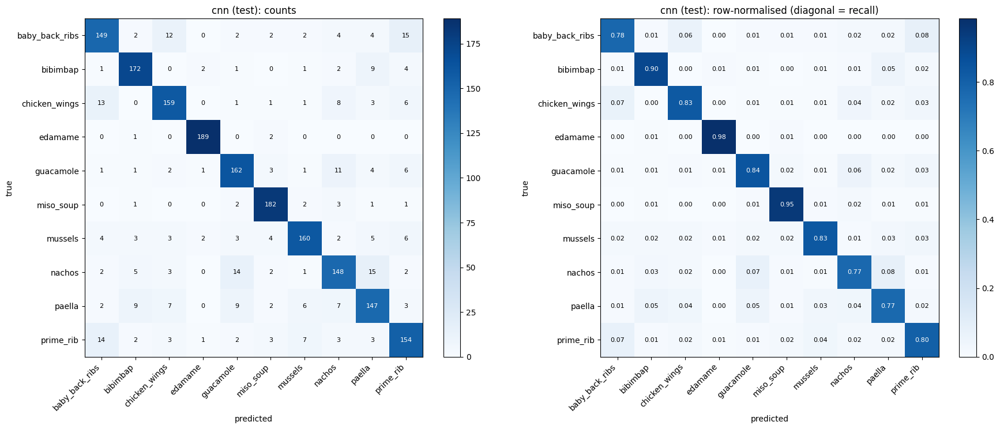

,true,predicted,count
0,baby_back_ribs,prime_rib,15
1,nachos,paella,15
2,nachos,guacamole,14
3,prime_rib,baby_back_ribs,14
4,chicken_wings,baby_back_ribs,13
5,baby_back_ribs,chicken_wings,12
6,guacamole,nachos,11
7,bibimbap,paella,9


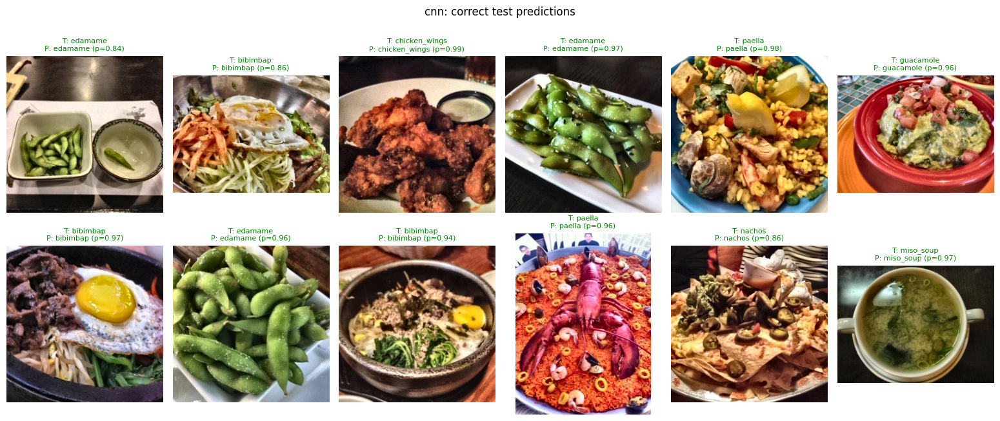

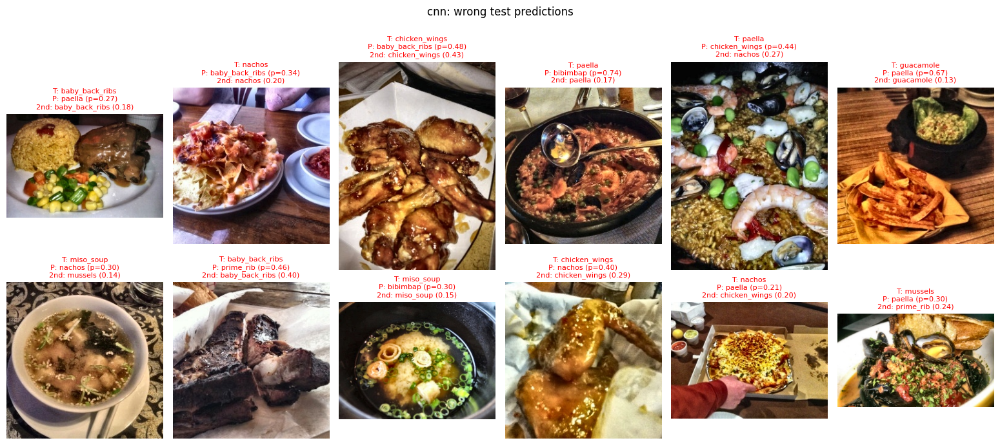

saved /Users/song-pongpanit/Documents/image_project/results/02_denoise_clahe/cnn/model.pt (18.9 MB) + config.json


In [75]:
best_cnn = cnn_grid.loc[cnn_grid.val_f1.idxmax()]
CHOSEN["cnn"] = best_cnn["name"]
cnn_cfg = {"n_blocks": int(best_cnn.n_blocks), "base": int(best_cnn.base), "dropout": float(best_cnn.dropout)}
cnn_model = load_trained(best_cnn.ckpt, lambda: SimpleCNN(**cnn_cfg))   # kept for Grad-CAM; its scores were saved during the grid
print("chosen:", best_cnn["name"], cnn_cfg, "|", best_cnn.stopped, "at epoch", int(best_cnn.epoch))
y_train, s_train = predict(cnn_model, "train")
report_model("cnn", *config_scores(best_cnn["name"]), {**cnn_cfg, **CNN_TRAIN, "epoch": int(best_cnn.epoch)},
             y_train=y_train, s_train=s_train)
save_final("cnn", "cnn", cnn_model, cnn_cfg)

In [87]:
summary(
    cnn_model,
    input_size=(1, 3, 224, 224),  # batch, channels, height, width
    col_names=("input_size", "output_size", "num_params", "trainable"),
    depth=5,
    device=str(DEVICE),
)

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #                   Trainable
SimpleCNN                                [1, 3, 224, 224]          [1, 10]                   --                        True
├─Sequential: 1-1                        [1, 3, 224, 224]          [1, 512, 7, 7]            --                        True
│    └─Conv2d: 2-1                       [1, 3, 224, 224]          [1, 32, 224, 224]         864                       True
│    └─BatchNorm2d: 2-2                  [1, 32, 224, 224]         [1, 32, 224, 224]         64                        True
│    └─ReLU: 2-3                         [1, 32, 224, 224]         [1, 32, 224, 224]         --                        --
│    └─Conv2d: 2-4                       [1, 32, 224, 224]         [1, 32, 224, 224]         9,216                     True
│    └─BatchNorm2d: 2-5                  [1, 32, 224, 224]         [1, 32, 224, 224]         64                        True
│    

## 7. Model 4 — ResNet-50 partial fine-tuning
Start from ImageNet weights. Freeze the backbone through layer3 and train layer4 and the new classification head; frozen BatchNorm statistics remain fixed.


resnet50_layer4: loaded saved model resnet50_layer4_81210e0a.pt


,unfreeze,lr,name,epoch,epochs_run,stopped,train_f1,val_f1
0,layer4,0.0003,resnet50_layer4,13,15,epoch limit,0.9998,0.9499


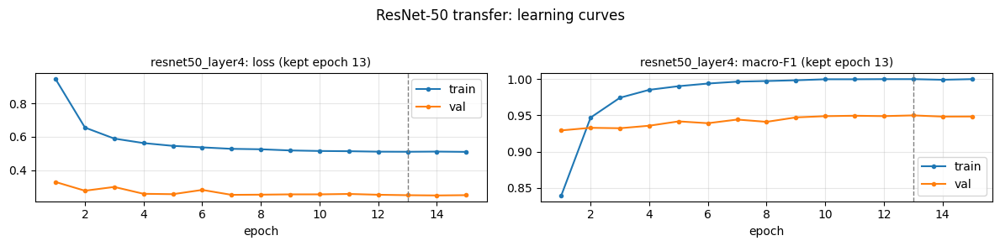

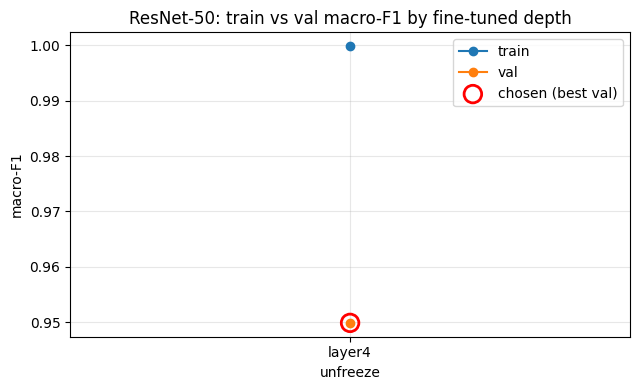

In [76]:
def make_resnet50(unfreeze, pretrained=True):
    m = torchvision.models.resnet50(weights=torchvision.models.ResNet50_Weights.IMAGENET1K_V2 if pretrained else None)
    m.fc = nn.Sequential(nn.Dropout(0.2), nn.Linear(m.fc.in_features, K))
    for p in m.parameters():
        p.requires_grad_(False)
    for part in {"fc": [m.fc], "layer4": [m.layer4, m.fc], "all": [m]}[unfreeze]:
        for p in part.parameters():
            p.requires_grad_(True)
    return m


rn_hists, rn_rows = {}, []
for cfg in RESNET_GRID:
    name = f"resnet50_{cfg['unfreeze']}"
    model, hist, ckpt = fit(name, lambda: make_resnet50(cfg["unfreeze"]), cfg, lr=cfg["lr"], **RESNET_TRAIN)
    rn_hists[name] = hist
    kept = hist[hist.best].iloc[0]
    if config_done(name, cfg) is None or ckpt.stat().st_mtime > (ALL_DIR / name / "metrics.json").stat().st_mtime:   # new or retrained
        record_config(name, "resnet50", "resnet50", model.eval(), cfg, {sp: predict(model, sp) for sp in ("val", "test")}, kept.train_f1)
    rn_rows.append({**cfg, "name": name, "epoch": int(kept.epoch), "epochs_run": len(hist),
                    "stopped": "early stop" if len(hist) < RESNET_TRAIN["max_epochs"] else "epoch limit",
                    "train_f1": kept.train_f1, "val_f1": kept.val_f1, "ckpt": str(ckpt)})
    del model
rn_grid = pd.DataFrame(rn_rows)
display(rn_grid.drop(columns="ckpt"))
plot_learning_curves(rn_hists, "ResNet-50 transfer: learning curves", "resnet_learning_curves")
plot_grid_summary(rn_grid, "unfreeze", "ResNet-50: train vs val macro-F1 by fine-tuned depth", "resnet_unfreeze")

chosen: resnet50_layer4 | epoch limit at epoch 13


,top1,top3,top5,macro_precision,macro_recall,macro_f1,mAP,n
train,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,5780
val,0.9497,0.9891,0.9974,0.9509,0.9497,0.9499,0.9811,1930
test,0.9531,0.9927,0.9969,0.9534,0.9531,0.9531,0.9784,1920


,precision,recall,f1,AP,support
baby_back_ribs,0.8922,0.9479,0.9192,0.9491,192
bibimbap,0.9639,0.9740,0.9689,0.9701,192
chicken_wings,0.9526,0.9427,0.9476,0.9844,192
edamame,1.0000,1.0000,1.0000,1.0000,192
guacamole,0.9534,0.9583,0.9558,0.9872,192
miso_soup,0.9846,1.0000,0.9922,0.9989,192
mussels,0.9634,0.9583,0.9608,0.9948,192
nachos,0.9511,0.9115,0.9309,0.9719,192
paella,0.9368,0.9271,0.9319,0.9622,192
prime_rib,0.9358,0.9115,0.9235,0.9659,192


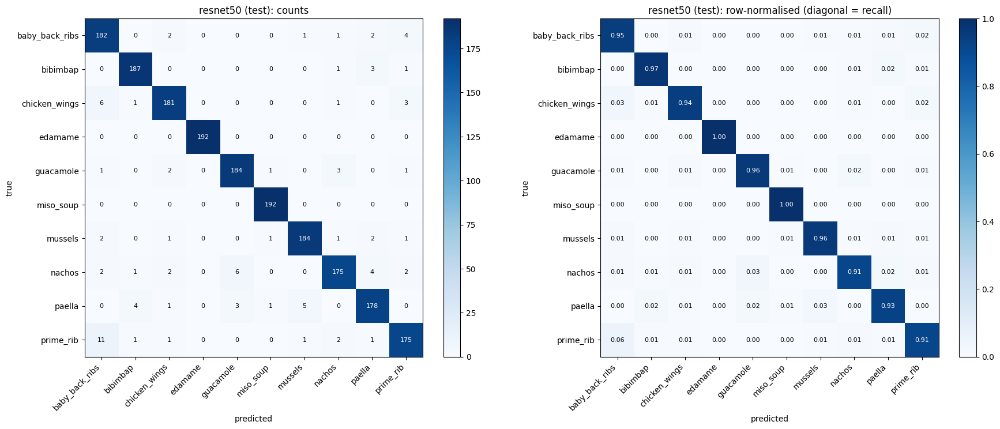

,true,predicted,count
0,prime_rib,baby_back_ribs,11
1,chicken_wings,baby_back_ribs,6
2,nachos,guacamole,6
3,paella,mussels,5
4,baby_back_ribs,prime_rib,4
5,nachos,paella,4
6,paella,bibimbap,4
7,bibimbap,paella,3


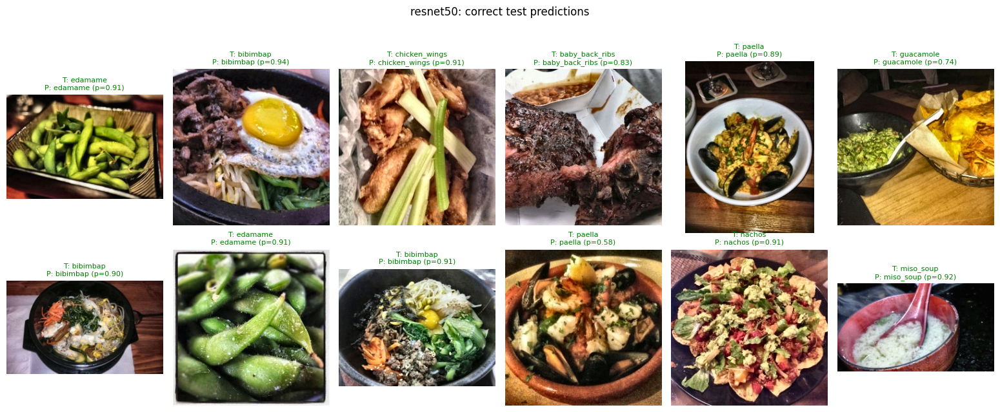

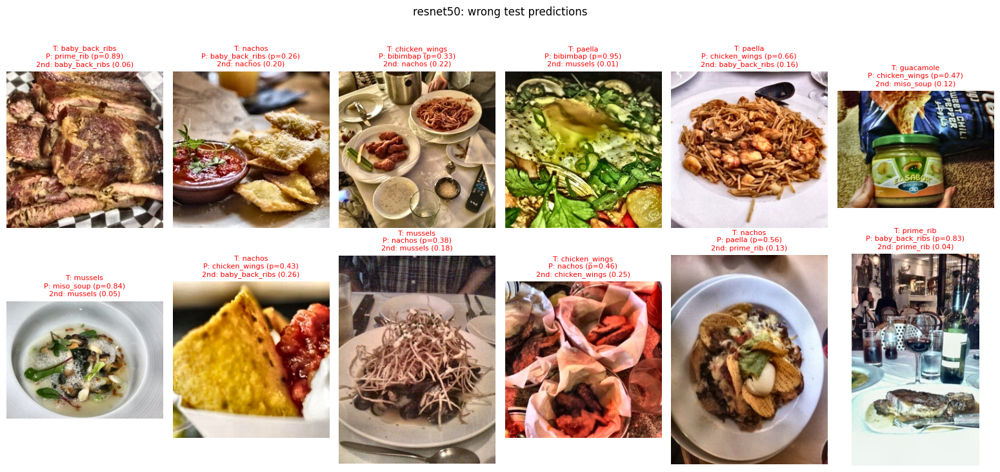

saved /Users/song-pongpanit/Documents/image_project/results/02_denoise_clahe/resnet50/model.pt (94.4 MB) + config.json


In [77]:
best_rn = rn_grid.loc[rn_grid.val_f1.idxmax()]
CHOSEN["resnet50"] = best_rn["name"]
rn_model = load_trained(best_rn.ckpt, lambda: make_resnet50(best_rn["unfreeze"]))   # kept for Grad-CAM
print("chosen:", best_rn["name"], "|", best_rn.stopped, "at epoch", int(best_rn.epoch))
y_train, s_train = predict(rn_model, "train")
report_model("resnet50", *config_scores(best_rn["name"]),
             {"unfreeze": best_rn["unfreeze"], "lr": float(best_rn.lr), **RESNET_TRAIN, "epoch": int(best_rn.epoch)},
             y_train=y_train, s_train=s_train)
save_final("resnet50", "resnet50", rn_model, {"unfreeze": best_rn["unfreeze"]})

## 8. Model comparison on this dataset
**8.1** the chosen model of each type (chosen on val, scored on test). **8.2** every config tried, with its test score: it shows how much each model depends on its setting. Bold = chosen on val. A config that was not chosen can score higher on test; picking it would be tuning on the test set.

,val_macro_f1,top1,top3,top5,macro_precision,macro_recall,macro_f1,mAP
clip_zeroshot,0.944,0.933,0.994,0.998,0.936,0.933,0.933,0.983
svm,0.345,0.345,0.640,0.815,0.347,0.345,0.345,0.326
cnn,0.850,0.845,0.964,0.984,0.844,0.845,0.844,0.916
resnet50,0.950,0.953,0.993,0.997,0.953,0.953,0.953,0.978


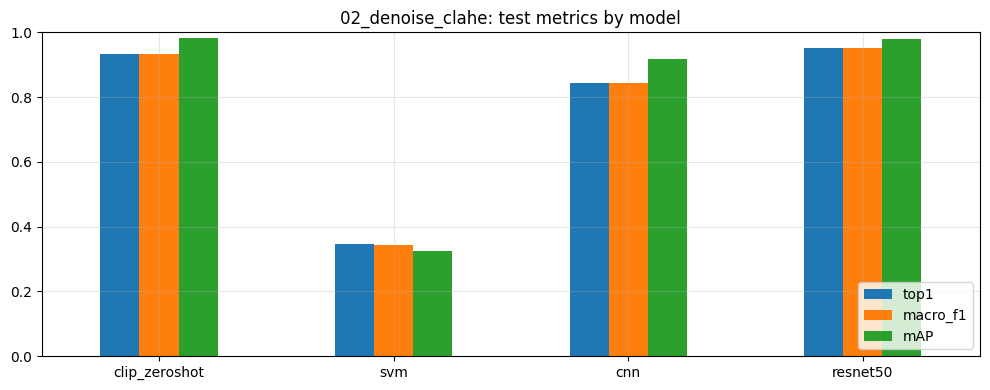

In [78]:
cols = ["top1", "top3", "top5", "macro_precision", "macro_recall", "macro_f1", "mAP"]
summary = pd.DataFrame({m: r["test"] for m, r in RESULTS.items()}).T[cols]
summary.insert(0, "val_macro_f1", [RESULTS[m]["val"]["macro_f1"] for m in summary.index])
display(summary.style.highlight_max(axis=0, color="#cde4ff").format("{:.3f}"))
summary.to_csv(OUT / "summary_test.csv")

fig, ax = plt.subplots(figsize=(10, 4))
summary[["top1", "macro_f1", "mAP"]].plot.bar(ax=ax, rot=0)
ax.set_ylim(0, 1); ax.set_title(f"{DATASET}: test metrics by model"); ax.legend(loc="lower right")
plt.tight_layout(); savefig(fig, "model_comparison"); plt.show()

## 9. Grad-CAM: what each model looks at
Grad-CAM weights the last convolutional feature map by the gradient of the predicted class score, so red = regions that pushed the model toward its prediction.
- CNN: last conv block. ResNet-50: `layer4`. CLIP ViT: the 7×7 patch tokens of the last transformer block (the same idea applied to tokens).
- The classical models have no gradients, so they have no Grad-CAM.

Two image sets:
1. **Fixed set**: 1 test image per class, picked by seed from the manifest. It is identical in 01 / 02 / 03 / 04, so you can put the notebooks side by side.
2. Correct and wrong predictions of ResNet-50 (the strongest trained model).

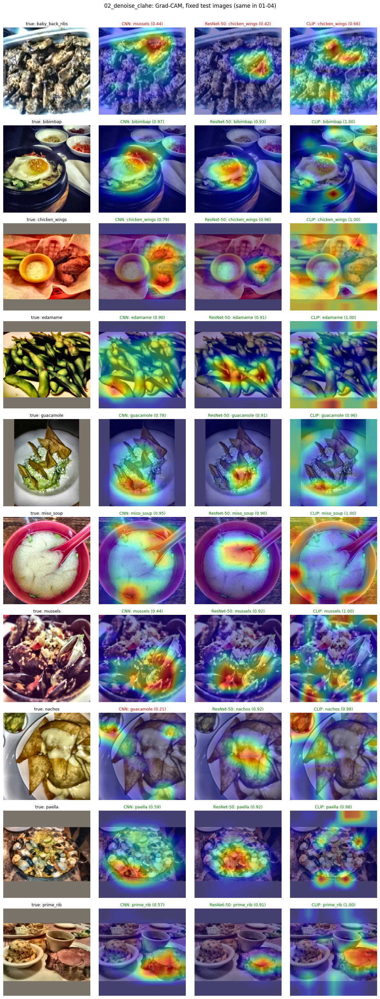

In [79]:
class GradCAM:
    def __init__(self, model, layer, tokens=False):
        self.model, self.tokens = model, tokens
        self.handle = layer.register_forward_hook(self._hook)

    def _hook(self, module, inp, out):
        self.acts = out
        out.register_hook(lambda g: setattr(self, "grads", g))

    def __call__(self, x):
        self.model.eval()
        x = x.to(DEVICE).requires_grad_(True)   # makes the hook fire even when the backbone is frozen
        logits = self.model(x)
        cls = logits.argmax(1)
        self.model.zero_grad(set_to_none=True)
        logits.gather(1, cls[:, None]).sum().backward()
        A, G = self.acts.detach(), self.grads.detach()
        if self.tokens:                         # (B, 1+N, C) ViT tokens -> (B, C, h, w), CLS token dropped
            side = int((A.shape[1] - 1) ** 0.5)
            A, G = [t[:, 1:].transpose(1, 2).reshape(t.shape[0], -1, side, side) for t in (A, G)]
        cam = F.relu((G.mean((2, 3), keepdim=True) * A).sum(1, keepdim=True))
        cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[:, 0]
        cam = (cam - cam.amin((1, 2), keepdim=True)) / (cam.amax((1, 2), keepdim=True) - cam.amin((1, 2), keepdim=True) + 1e-8)
        return cam.cpu().numpy(), logits.detach().softmax(1).cpu().numpy()

    def remove(self):
        self.handle.remove()


cam_models = {   # name -> (model, target layer, transform, token input?)
    "CNN": (cnn_model, cnn_model.features[-2], eval_tf, False),
    "ResNet-50": (rn_model, rn_model.layer4, eval_tf, False),
    "CLIP": (clip_model, clip_model.clip.vision_model.encoder.layers[-1].layer_norm1, clip_tf, True),
}


def gradcam_grid(frame, title, name):
    cams = {m: GradCAM(model, layer, tok) for m, (model, layer, _, tok) in cam_models.items()}
    fig, axes = plt.subplots(len(frame), 1 + len(cams), figsize=(3 * (1 + len(cams)), 3.1 * len(frame)), squeeze=False)
    try:
        for row, (_, r) in zip(axes, frame.iterrows()):
            img = Image.open(r.path).convert("RGB")
            shown = np.asarray(pad_to_square(img).resize((IMG_SIZE, IMG_SIZE)))
            row[0].imshow(shown); row[0].set_title(f"true: {r.label}", fontsize=9)
            for ax, (m, cam) in zip(row[1:], cams.items()):
                heat, prob = cam(cam_models[m][2](img)[None])
                p = prob[0].argmax()
                ax.imshow(shown); ax.imshow(heat[0], cmap="jet", alpha=0.45)
                ax.set_title(f"{m}: {CLASSES[p]} ({prob[0, p]:.2f})", fontsize=9, color="green" if p == r.y else "red")
            for ax in row: ax.axis("off")
    finally:
        for c in cams.values(): c.remove()
    finish(fig, title, name)


fixed = splits["test"].groupby("label", group_keys=False).sample(1, random_state=SEED).reset_index(drop=True)
fixed[["relpath"]].to_csv(OUT / "gradcam_fixed_images.csv", index=False)
gradcam_grid(fixed, f"{DATASET}: Grad-CAM, fixed test images (same in 01-04)", "gradcam_fixed")

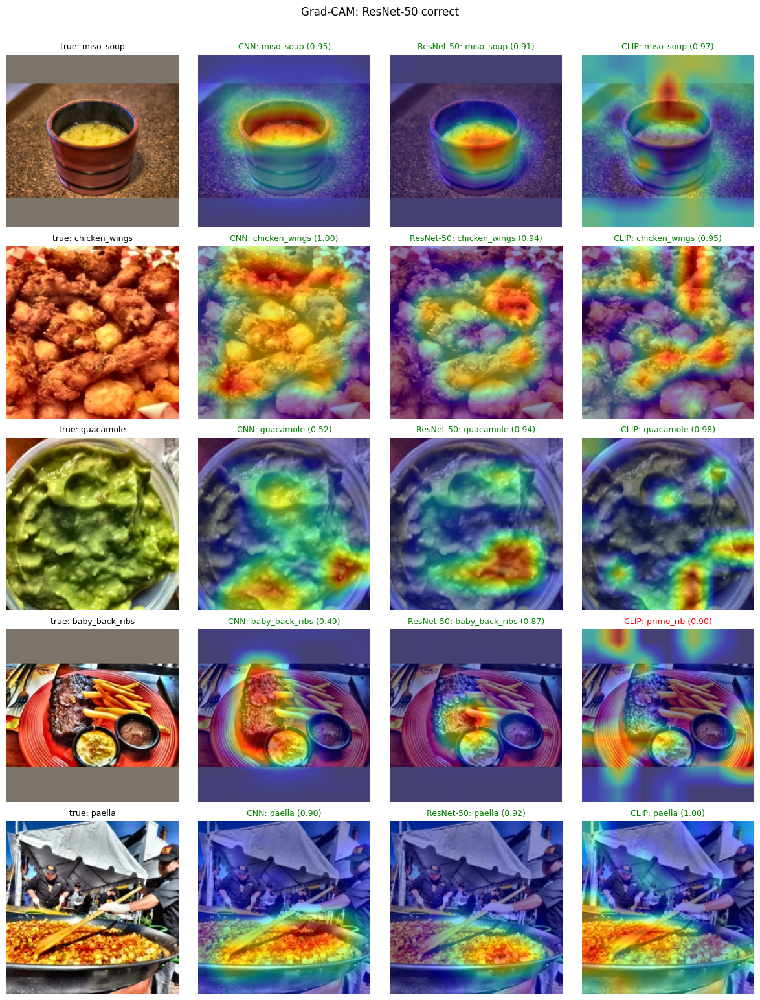

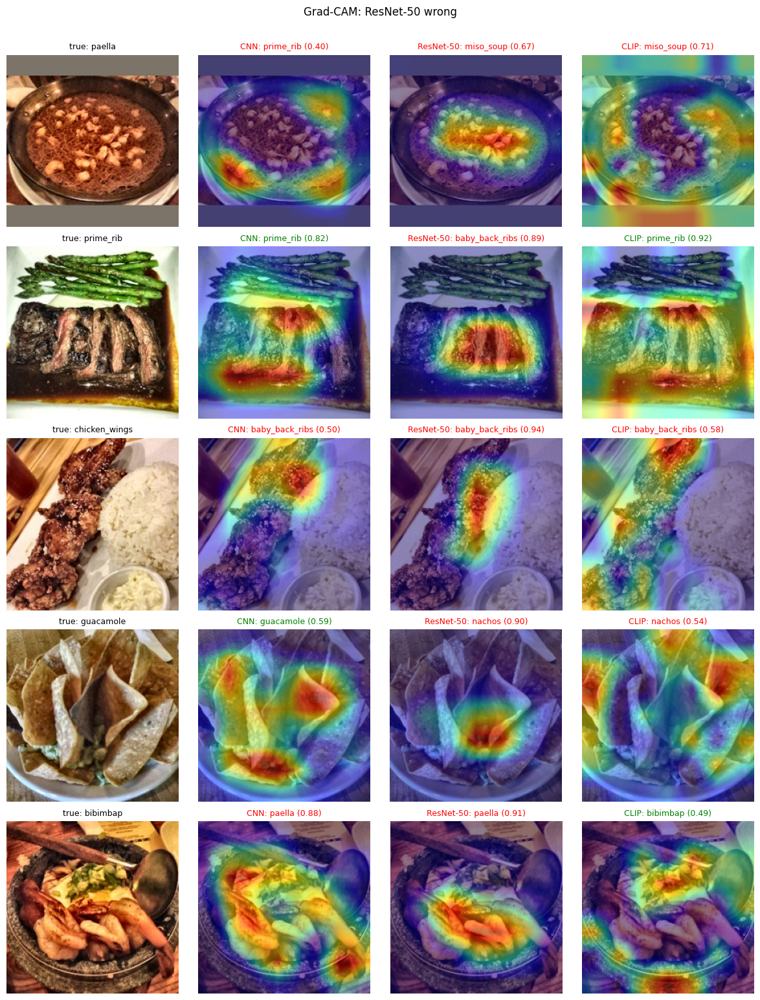

In [80]:
rn_test = pd.read_csv(OUT / "resnet50" / "predictions_test.csv")
right_pool = splits["test"][rn_test.y_true.values == rn_test.y_pred.values]
right = right_pool.sample(min(5, len(right_pool)), random_state=SEED)
wrong_pool = splits["test"][rn_test.y_true.values != rn_test.y_pred.values]
wrong = wrong_pool.sample(min(5, len(wrong_pool)), random_state=SEED)
if len(right):
    gradcam_grid(right.reset_index(drop=True), "Grad-CAM: ResNet-50 correct", "gradcam_correct")
if len(wrong):
    gradcam_grid(wrong.reset_index(drop=True), "Grad-CAM: ResNet-50 wrong", "gradcam_wrong")

## 10. Reload the saved models
Sections 4–7 already score the test set with the model each one just trained, still in memory. This section is separate: it rebuilds each final model **from its saved file**,
so it works in a fresh kernel, on another machine, or in a teammate's notebook. Run sections 0–3 first (settings, paths, imports, data, transforms, metric functions), then this section.
It does not need the training sections: the model classes and feature function are defined here again (identical to sections 5–7).

- `load_model(name, dataset)` reads `results/<dataset>/<name>/config.json` and rebuilds the model.
- **12.1** `predict_saved(name)` scores the whole test set with the reloaded model and checks the numbers against `metrics.json` from training. If they match, the saved file is correct.
- **12.2** `classify(path, name)` gives the top-k classes for one image.

Every model expects the same preprocessing as its dataset. A model trained on 04 expects a denoised, CLAHE'd, DINO-cropped image, so an outside photo
should go through the team's 02/04 pipeline first. The example uses a test image from the dataset, which is already preprocessed.

In [81]:
import joblib
import cv2
from skimage.feature import hog, local_binary_pattern
from transformers import CLIPModel


class SimpleCNN(nn.Module):
    def __init__(self, n_blocks=4, base=32, dropout=0.3, n_classes=K):
        super().__init__()
        layers, c_in = [], 3
        for i in range(n_blocks):
            c = base * 2 ** i
            layers += [nn.Conv2d(c_in, c, 3, padding=1, bias=False), nn.BatchNorm2d(c), nn.ReLU(inplace=True),
                       nn.Conv2d(c, c, 3, padding=1, bias=False), nn.BatchNorm2d(c), nn.ReLU(inplace=True),
                       nn.MaxPool2d(2)]
            c_in = c
        self.features = nn.Sequential(*layers)
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(dropout), nn.Linear(c_in, n_classes))

    def forward(self, x):
        return self.head(self.features(x))


def make_resnet50(unfreeze, pretrained=True):
    m = torchvision.models.resnet50(weights=torchvision.models.ResNet50_Weights.IMAGENET1K_V2 if pretrained else None)
    m.fc = nn.Sequential(nn.Dropout(0.2), nn.Linear(m.fc.in_features, K))
    for p in m.parameters():
        p.requires_grad_(False)
    for part in {"fc": [m.fc], "layer4": [m.layer4, m.fc], "all": [m]}[unfreeze]:
        for p in part.parameters():
            p.requires_grad_(True)
    return m


class CLIPZeroShot(nn.Module):
    def __init__(self, clip, text_emb):
        super().__init__()
        self.clip = clip
        self.register_buffer("text_emb", text_emb)

    def forward(self, x):
        f = self.clip.visual_projection(self.clip.vision_model(pixel_values=x).pooler_output)
        return self.clip.logit_scale.exp() * F.normalize(f, dim=-1) @ self.text_emb.T


def handcrafted(path):
    rgb = np.asarray(pad_to_square(Image.open(path).convert("RGB")).resize((128, 128), Image.BILINEAR))
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    return hog(gray, orientations=9, pixels_per_cell=(16, 16),
               cells_per_block=(2, 2), block_norm="L2-Hys").astype(np.float32)


_LOADED = {}   # (dataset, name) -> (model, config), so repeated calls don't reload from disk


def load_model(name, dataset=DATASET):
    """Rebuild a saved final model from results/<dataset>/<name>/. Returns (model, config)."""
    if (dataset, name) in _LOADED:
        return _LOADED[(dataset, name)]
    d = OUT.parent / dataset / name
    assert (d / "config.json").exists(), f"no saved model in {d}: run that model's section first"
    with open(d / "config.json") as f:
        cfg = json.load(f)
    assert cfg["classes"] == CLASSES, "saved model was trained on different classes"
    if cfg["kind"] == "sklearn":
        model = joblib.load(d / cfg["file"])
    else:
        ck = torch.load(d / cfg["file"], map_location="cpu")
        if cfg["kind"] == "cnn":
            model = SimpleCNN(**ck["arch"])
            model.load_state_dict(ck["state_dict"])
        elif cfg["kind"] == "resnet50":
            model = make_resnet50(ck["arch"]["unfreeze"], pretrained=False)
            model.load_state_dict(ck["state_dict"])
        elif cfg["kind"] == "clip":
            clip_m = CLIPModel.from_pretrained(ck["arch"]["clip_id"])
            model = CLIPZeroShot(clip_m, ck["text_emb"])
        model = model.to(DEVICE).eval()
    _LOADED[(dataset, name)] = (model, cfg)
    print(f"loaded {name} ({dataset}): val macro-F1 {cfg['val_macro_f1']}, test macro-F1 {cfg['test_macro_f1']}")
    return model, cfg


@torch.no_grad()
def resnet_embedding_one(img):
    if "embedder" not in _LOADED:
        m = torchvision.models.resnet50(weights=torchvision.models.ResNet50_Weights.IMAGENET1K_V2)
        m.fc = nn.Identity()
        _LOADED["embedder"] = m.to(DEVICE).eval()
    return _LOADED["embedder"](eval_tf(img)[None].to(DEVICE)).cpu().numpy()


@torch.no_grad()
def predict_saved(name, split="test"):
    """Scores of a reloaded model on a whole split of this notebook's dataset -> (y, scores)."""
    model, cfg = load_model(name, DATASET)
    frame = splits[split]
    if cfg["kind"] == "sklearn":
        if cfg["arch"]["features"] == "hog":
            from joblib import Parallel, delayed
            feats = np.stack(Parallel(n_jobs=-1, batch_size=32)(delayed(handcrafted)(p) for p in frame.path))
        else:
            feats = np.concatenate([resnet_embedding_one(Image.open(p).convert("RGB")) for p in frame.path])
        scores = model.predict_proba(feats) if hasattr(model, "predict_proba") else model.decision_function(feats)
    else:
        tf = clip_tf if cfg["kind"] == "clip" else eval_tf
        scores = np.concatenate([model(x.to(DEVICE)).float().softmax(1).cpu().numpy() for x, _ in make_loader(split, tf)])
    return frame.y.values, scores


@torch.no_grad()
def classify(path, name, dataset=DATASET, k=3, show=True):
    """Top-k prediction of one saved model for one image file."""
    model, cfg = load_model(name, dataset)
    img = Image.open(path).convert("RGB")
    if cfg["kind"] == "sklearn":
        feats = handcrafted(path)[None] if cfg["arch"]["features"] == "hog" else resnet_embedding_one(img)
        scores = model.predict_proba(feats)[0] if hasattr(model, "predict_proba") else model.decision_function(feats)[0]
    else:
        tf = clip_tf if cfg["kind"] == "clip" else eval_tf
        scores = model(tf(img)[None].to(DEVICE)).float().softmax(1)[0].cpu().numpy()
    top = np.argsort(-scores)[:k]
    result = [(CLASSES[i], float(scores[i])) for i in top]
    if show:
        fig, ax = plt.subplots(figsize=(3.2, 3.6))
        ax.imshow(img); ax.axis("off")
        ax.set_title(f"{name} ({dataset[:2]})\n" + "\n".join(f"{c}: {v:.2f}" for c, v in result), fontsize=9)
        plt.show()
    return result

In [82]:
# 12.1 whole test set from the saved files, compared with the numbers recorded at training time
rows = []
for name in ["clip_zeroshot", "svm", "cnn", "resnet50"]:
    if not (OUT / name / "config.json").exists():
        print(f"{name}: not saved yet"); continue
    y, sc = predict_saved(name, "test")
    m, _ = compute_metrics(y, sc)
    with open(OUT / name / "metrics.json") as f:
        trained = json.load(f)["test"]
    rows.append({"model": name, **{k: m[k] for k in ("top1", "top3", "top5", "macro_f1", "mAP")},
                 "macro_f1_at_training": trained["macro_f1"],
                 "match": abs(m["macro_f1"] - trained["macro_f1"]) < 1e-3})
if rows:
    reloaded = pd.DataFrame(rows).set_index("model")
    display(reloaded)
    if not reloaded.match.all():
        print("a reloaded model differs from its training-time result: check that the dataset and settings are the same as when it was saved")

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 91220.38it/s]


loaded clip_zeroshot (02_denoise_clahe): val macro-F1 0.9443747009044474, test macro-F1 0.9332265761893378
loaded svm (02_denoise_clahe): val macro-F1 0.3445475103621904, test macro-F1 0.3445128094028071
loaded cnn (02_denoise_clahe): val macro-F1 0.8495139992726344, test macro-F1 0.8443861795047288
loaded resnet50 (02_denoise_clahe): val macro-F1 0.9498928959079398, test macro-F1 0.9530946628554876


,top1,top3,top5,macro_f1,mAP,macro_f1_at_training,match
model,,,,,,,
clip_zeroshot,0.9333,0.9943,0.9979,0.9332,0.9834,0.9332,True
svm,0.3448,0.6396,0.8146,0.3445,0.3259,0.3445,True
cnn,0.8448,0.9635,0.9839,0.8444,0.9162,0.8444,True
resnet50,0.9531,0.9927,0.9969,0.9531,0.9784,0.9531,True


true label: baby_back_ribs | test/baby_back_ribs/915852.jpg
clip_zeroshot  [('baby_back_ribs', 0.49012792110443115), ('prime_rib', 0.4756067395210266), ('chicken_wings', 0.017584608867764473)]
svm            [('chicken_wings', 9.274056839085784), ('mussels', 8.261727204051152), ('nachos', 7.272787102219593)]
cnn            [('baby_back_ribs', 0.8701914548873901), ('bibimbap', 0.05782667174935341), ('miso_soup', 0.021337570622563362)]
resnet50       [('baby_back_ribs', 0.9491201043128967), ('mussels', 0.008166931569576263), ('prime_rib', 0.006777449510991573)]


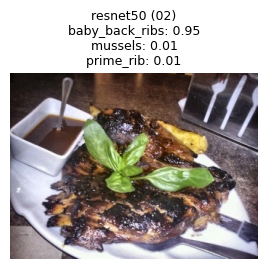

In [83]:
# 12.2 one image: every saved model on the same test image (swap in any image path)
example = splits["test"].sample(1, random_state=SEED).iloc[0]
print("true label:", example.label, "|", example.relpath)
for name in ["clip_zeroshot", "svm", "cnn", "resnet50"]:
    if (OUT / name / "config.json").exists():
        print(f"{name:14s}", classify(example.path, name, show=False))
    else:
        print(f"{name:14s} not saved yet")
if (OUT / "resnet50" / "config.json").exists():
    classify(example.path, "resnet50")

## 11. Export predictions for review

Run sections 0–3 and section 10 first, after saving the chosen models. This cell evaluates each available saved model on train without augmentation and reuses its saved validation/test predictions. It writes `predictions_<split>.csv` and `errors_<split>.csv` under each model, plus `model_predictions_<split>.csv` to compare all models on the same image. `image_path` is a path on the current machine or Colab runtime. SVM scores are decision values, not probabilities.


In [84]:
def export_prediction_review():
    """Export chosen models' train/val/test predictions and errors without retraining."""
    names = [name for name in ("clip_zeroshot", "svm", "cnn", "resnet50")
             if (OUT / name / "config.json").exists()]
    if not names:
        print("No saved models yet. Run a model section first.")
        return

    for split in ("train", "val", "test"):
        frame = splits[split]
        comparison = frame[["relpath", "label"]].copy()
        comparison["image_path"] = frame.path.values
        for name in names:
            prediction_file = OUT / name / f"predictions_{split}.csv"
            if split == "train" or not prediction_file.exists():
                y, scores = predict_saved(name, split)
                if not np.array_equal(y, frame.y.to_numpy()):
                    raise ValueError(f"{name} {split}: labels do not match dataset order")
                save_predictions(name, split, y, scores)
            predictions = pd.read_csv(prediction_file)
            if (len(predictions) != len(frame) or
                    predictions.relpath.tolist() != frame.relpath.tolist() or
                    predictions.label.tolist() != frame.label.tolist()):
                raise ValueError(f"{prediction_file} does not match the current dataset split; rerun that model")
            predictions["is_correct"] = predictions.y_true == predictions.y_pred
            predictions["image_path"] = frame.path.values
            predictions.to_csv(prediction_file, index=False)
            errors = predictions.loc[~predictions.is_correct]
            errors.to_csv(OUT / name / f"errors_{split}.csv", index=False)
            comparison[f"{name}_pred"] = predictions.pred_label.values
            comparison[f"{name}_correct"] = predictions.is_correct.values
            print(f"{split} | {name}: {len(errors)}/{len(predictions)} wrong")
        comparison.to_csv(OUT / f"model_predictions_{split}.csv", index=False)
        print(f"Saved: {OUT / f'model_predictions_{split}.csv'}")


export_prediction_review()


train | clip_zeroshot: 381/5780 wrong
train | svm: 0/5780 wrong
train | cnn: 280/5780 wrong
train | resnet50: 0/5780 wrong
Saved: /Users/song-pongpanit/Documents/image_project/results/02_denoise_clahe/model_predictions_train.csv
val | clip_zeroshot: 107/1930 wrong
val | svm: 1263/1930 wrong
val | cnn: 291/1930 wrong
val | resnet50: 97/1930 wrong
Saved: /Users/song-pongpanit/Documents/image_project/results/02_denoise_clahe/model_predictions_val.csv
test | clip_zeroshot: 128/1920 wrong
test | svm: 1258/1920 wrong
test | cnn: 298/1920 wrong
test | resnet50: 90/1920 wrong
Saved: /Users/song-pongpanit/Documents/image_project/results/02_denoise_clahe/model_predictions_test.csv


## Report checklist
- Record dataset manifest, split counts and duplicate-check limitations.
- Explain CLIP prompt selection, HOG + SVM hyperparameters, CNN architecture, and which ResNet layers were trained.
- Report validation selection and held-out test metrics, confusion matrices, examples and Grad-CAM.
- Smoke results are only pipeline checks; use full-run results for conclusions.
